# Analyse non supervisée et labels faibles

**Projet :** BrainScanAI - détection semi-supervisée de tumeurs cérébrales  
**Étape :** 3 - Réalisez une analyse non supervisée  
**Auteur :** Kilian Lefevre  

---

## Objectif du notebook

Les caractéristiques extraites à l'étape précédente servent à **regrouper les images**, puis à attribuer un **label faible** aux images non annotées. Ce notebook répond aux questions suivantes :

- Comment réserver un jeu de test et un jeu de validation avant toute transformation des features ?
- Les images forment-elles deux groupes visibles après réduction de dimension ?
- Que donne K-Means, comparé aux labels forts ?
- Un seuil de décision plus prudent aide-t-il à repérer les cancers ?
- Combien de groupes retenir, et DBSCAN fait-il mieux ?
- Quels labels faibles obtient-on pour les images non annotées, avec quelle confiance ?
- Où le label faible se trompe-t-il ?
- Que capturent les clusters : la pathologie, ou des indices liés à l'acquisition ?
- Que regardent les deux groupes dans l'image ?
- Les labels faibles sont-ils assez fiables pour l'étape suivante ?

**Prérequis :** le manifeste dédupliqué (`data/interim/manifest.csv`) et les features (`data/processed/features_resnet18_layer{3,4}.npz`), produits par `make data` et `make features`.

## 1. Chargement

On charge le manifeste et les deux matrices de features (`layer3`, 256 dimensions, et `layer4`, 512 dimensions). L'alignement avec les `image_id` du manifeste est vérifié.

In [1]:
import cv2
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    f1_score,
    recall_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors

from brain_mri.attention import feature_maps, load_classifier
from brain_mri.config import (
    FIGURES_DIR,
    IMAGE_SIZE,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
)
from brain_mri.dataset import read_manifest, split_dataset
from brain_mri.features import (
    EXTRACTION_LAYERS,
    MODEL_NAME,
    load_features,
    preprocess_equalized,
    select_device,
)
from brain_mri.modeling.preprocessing import (
    N_COMPONENTS,
    RANDOM_STATE,
    fit_pca,
    fit_standardizer,
)
from brain_mri.modeling.unsupervised import (
    REFERENCE_LAYER,
    ari_without_noise,
    build_weak_labels,
    encode_labels,
    evaluate_weak_labels,
    kmeans_confidence,
    majority_mapping,
    to_weak_labels,
)
from brain_mri.quality import BACKGROUND_LEVEL
from utils.mlflow_utils import (
    log_dataset,
    log_figure,
    log_metrics,
    log_params,
    log_sklearn_model,
    resume_run,
    setup_mlflow,
    start_run,
)

pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK = "03.01-kl-unsupervised-analysis"
MANIFEST_PATH = INTERIM_DATA_DIR / "manifest.csv"

print(f"Suivi MLflow : {setup_mlflow()}")

manifest = read_manifest(MANIFEST_PATH)

raw_features = {}
for layer in EXTRACTION_LAYERS:
    path = PROCESSED_DATA_DIR / f"features_{MODEL_NAME}_{layer}.npz"
    image_ids, matrix = load_features(path)
    assert (image_ids == manifest["image_id"].to_numpy()).all()
    raw_features[layer] = matrix
    print(
        f"{layer} : {matrix.shape[0]:,} images × {matrix.shape[1]:,} dimensions"
    )

Suivi MLflow : sqlite:///<PROJECT_ROOT>/mlflow.db
layer3 : 1,291 images × 256 dimensions
layer4 : 1,291 images × 512 dimensions


## 2. Découpage entraînement, validation et test

La standardisation, la PCA et le clustering **s'ajustent sur des données**. Si le jeu de test participait à cet ajustement, il ne serait plus « jamais vu ». On définit donc les trois jeux **avant** toute transformation :

- le **test** (15 images) sert à l'évaluation finale ;
- la **validation** (14 images) sert aux vérifications en cours de route et, à l'étape suivante, à l'arrêt anticipé de l'entraînement ;
- l'**entraînement** regroupe les 68 autres images annotées et **toutes les images non annotées**. C'est sur lui que s'ajustent la standardisation, la PCA et les clusterings.

Test et validation sont tirés **parmi les images annotées uniquement**, car il faut des labels forts pour les évaluer. Le tirage est **stratifié** : autant de `cancer` que de `normal`. Les images non annotées ne forment **aucune classe** : elles servent à l'apprentissage non supervisé.

Le découpage est implémenté dans `brain_mri.dataset` (`split_dataset`) et enregistré dans `data/processed/split.csv`, pour que l'étape suivante réutilise exactement les mêmes images.

In [2]:
split = split_dataset(manifest)
split.to_csv(PROCESSED_DATA_DIR / "split.csv", index=False)
manifest["split"] = split["split"].to_numpy()

is_train = (manifest["split"] == "train").to_numpy()
is_validation = (manifest["split"] == "validation").to_numpy()
is_test = (manifest["split"] == "test").to_numpy()
is_labeled = manifest["is_labeled"].to_numpy()
# Label fort : 1 = cancer, 0 = normal, NaN = image non annotée.
strong_label = encode_labels(manifest["label"])

summary = (
    manifest.assign(label=manifest["label"].fillna("non annotée"))
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
    .loc[["train", "validation", "test"]]
)
summary["total"] = summary.sum(axis=1)
display(summary)

assert not (is_train & is_validation).any()
assert not (is_train & is_test).any()
assert not (is_validation & is_test).any()
assert is_labeled[is_validation | is_test].all()

label,cancer,non annotée,normal,total
split,,,,
train,35,1194,33,1262
validation,7,0,7,14
test,8,0,7,15


## 3. Standardisation

Chaque dimension est centrée et réduite (moyenne 0, écart-type 1), pour qu'aucune dimension de grande amplitude ne domine les distances. Le `StandardScaler` est **ajusté sur l'entraînement uniquement**, puis appliqué tel quel à la validation et au test. Cette étape est implémentée dans `brain_mri.modeling.preprocessing` (`fit_standardizer`).

In [3]:
is_held_out = ~is_train

scalers = {}
scaled_features = {}
rows = []
for layer, matrix in raw_features.items():
    scalers[layer] = fit_standardizer(matrix, is_train)
    scaled = scalers[layer].transform(matrix)
    scaled_features[layer] = scaled
    rows.append(
        {
            "couche": layer,
            "moyenne entraînement": np.abs(scaled[is_train].mean(axis=0)).max(),
            "écart-type entraînement": scaled[is_train].std(axis=0).mean(),
            "moyenne hors entraînement": np.abs(
                scaled[is_held_out].mean(axis=0)
            ).mean(),
            "écart-type hors entraînement": scaled[is_held_out]
            .std(axis=0)
            .mean(),
        }
    )
display(pd.DataFrame(rows).set_index("couche").round(3))

,moyenne entraînement,écart-type entraînement,moyenne hors entraînement,écart-type hors entraînement
couche,,,,
layer3,0.0,1.0,0.249,1.028
layer4,0.0,1.0,0.212,0.961


Hors entraînement, les moyennes s'écartent de 0, surtout pour `layer3` : les images annotées ne suivent pas exactement la distribution des non annotées.

## 4. Réduction de dimension

Deux outils, avec deux rôles différents :

- La **PCA** est linéaire et reproductible. Elle sert à **visualiser** (deux premières composantes) et à **réduire** les features avant le clustering : en dimension 256 ou 512, les distances deviennent peu discriminantes, ce qui pénalise surtout les méthodes par densité. On garde **50 composantes**.
- Le **t-SNE** conserve les voisinages locaux et sépare mieux les groupes, mais il déforme les distances globales et ne peut pas projeter de nouvelles images. Il ne sert donc **qu'à la visualisation**, sur l'entraînement.

La PCA est ajustée sur l'entraînement, puis appliquée à la validation et au test. Elle est implémentée dans `brain_mri.modeling.preprocessing` (`fit_pca`).

,layer3,layer4
10 composantes,0.579,0.426
20 composantes,0.701,0.553
50 composantes,0.844,0.730
100 composantes,0.933,0.854
200 composantes,0.991,0.947


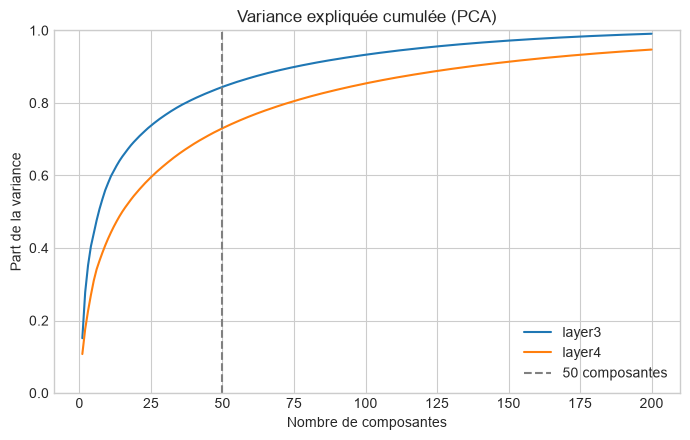

In [4]:
CURVE_COMPONENTS = 200

pcas = {}
reduced = {}
variance = {}
for layer, matrix in scaled_features.items():
    curve = PCA(n_components=CURVE_COMPONENTS, random_state=RANDOM_STATE)
    curve.fit(matrix[is_train])
    variance[layer] = np.cumsum(curve.explained_variance_ratio_)

    pcas[layer] = fit_pca(matrix, is_train)
    reduced[layer] = pcas[layer].transform(matrix)

checkpoints = [10, 20, 50, 100, 200]
display(
    pd.DataFrame(
        {
            layer: [curve[k - 1] for k in checkpoints]
            for layer, curve in variance.items()
        },
        index=[f"{k} composantes" for k in checkpoints],
    ).round(3)
)

figure, axis = plt.subplots(figsize=(7, 4.5))
for layer, curve in variance.items():
    axis.plot(np.arange(1, CURVE_COMPONENTS + 1), curve, label=layer)
axis.axvline(
    N_COMPONENTS,
    color="grey",
    linestyle="--",
    label=f"{N_COMPONENTS} composantes",
)
axis.set(
    title="Variance expliquée cumulée (PCA)",
    xlabel="Nombre de composantes",
    ylabel="Part de la variance",
    ylim=(0, 1),
)
axis.legend()
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "variance-expliquee-pca.png", dpi=120, bbox_inches="tight"
)
plt.show()

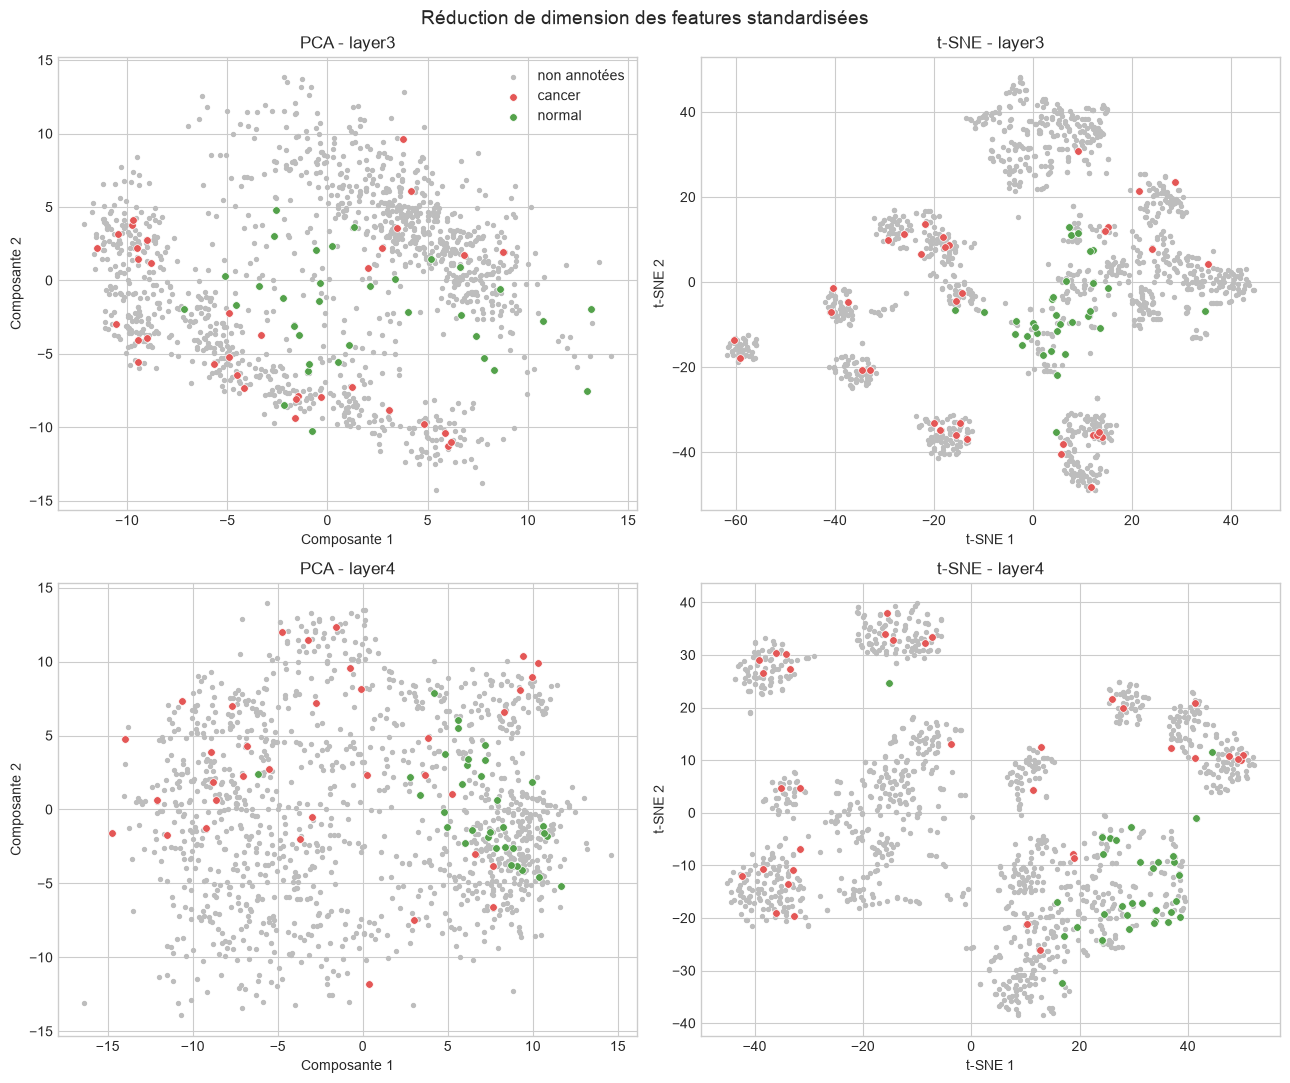

In [5]:
# Tableaux restreints à l'entraînement, utilisés pour le clustering.
train_labeled = is_labeled[is_train]
train_strong = strong_label[is_train]
train_reduced = {layer: matrix[is_train] for layer, matrix in reduced.items()}
train_scaled = {
    layer: matrix[is_train] for layer, matrix in scaled_features.items()
}

tsne_coordinates = {
    layer: TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        random_state=RANDOM_STATE,
    ).fit_transform(matrix)
    for layer, matrix in train_reduced.items()
}

LABEL_COLORS = ((1, "cancer", "#E45756"), (0, "normal", "#54A24B"))


def scatter_labels(axis, coordinates, title, xlabel, ylabel):
    """Nuage 2D : annotées colorées par label, non annotées en gris."""
    unlabeled = ~train_labeled
    axis.scatter(
        coordinates[unlabeled, 0],
        coordinates[unlabeled, 1],
        s=8,
        color="#BDBDBD",
        label="non annotées",
    )
    for value, name, color in LABEL_COLORS:
        mask = train_strong == value
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=30,
            color=color,
            edgecolor="white",
            linewidth=0.5,
            label=name,
        )
    axis.set(title=title, xlabel=xlabel, ylabel=ylabel)


figure, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, layer in zip(axes, EXTRACTION_LAYERS, strict=True):
    scatter_labels(
        row[0],
        train_reduced[layer][:, :2],
        f"PCA - {layer}",
        "Composante 1",
        "Composante 2",
    )
    scatter_labels(
        row[1],
        tsne_coordinates[layer],
        f"t-SNE - {layer}",
        "t-SNE 1",
        "t-SNE 2",
    )
axes[0, 0].legend()
figure.suptitle(
    "Réduction de dimension des features standardisées", fontsize=14
)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "reduction-2d-labels.png", dpi=120, bbox_inches="tight"
)
plt.show()

Sur `layer4`, les `normal` annotées se regroupent surtout en bas à droite de la PCA et dans une même zone du t-SNE, alors que les `cancer` sont plus dispersées, avec un recouvrement. Sur `layer3`, les `cancer` forment surtout des îlots à gauche et en bas, et les `normal` sont dispersées au centre.

## 5. K-Means

On cherche **deux groupes**, comme dans le jeu annoté. Le clustering s'ajuste sur l'entraînement, **sans utiliser les labels**.

La qualité se mesure par l'**ARI** (*Adjusted Rand Index*) entre les clusters et les labels forts :

- 1 pour un accord parfait, **0 pour un accord équivalent au hasard**, négatif en dessous ;
- insensible au numéro attribué aux clusters.

L'ARI se calcule sur les **images annotées de l'entraînement** (68 images) : les images non annotées participent au clustering, mais n'ont pas de label pour être évaluées. Avec si peu d'images, les valeurs sont **indicatives**.

In [6]:
all_runs = []
train_table = manifest.loc[
    is_train, ["image_id", "subset", "label", "is_labeled", "split"]
]


def purity(cluster_labels, true_labels):
    """Part des images annotées de la classe majoritaire de leur cluster."""
    known = ~np.isnan(true_labels)
    clusters, classes = cluster_labels[known], true_labels[known].astype(int)
    majority = sum(
        np.bincount(classes[clusters == cluster]).max()
        for cluster in np.unique(clusters)
    )
    return majority / known.sum()


def record(
    layer, method, parameters, cluster_labels, keep=True, models=None, **extra
):
    """Enregistre un clustering de l'entraînement et ses mesures.

    Chaque clustering est un run MLflow : ses paramètres, le jeu d'entraînement
    utilisé, ses mesures et, si `models` est donné, les modèles ajustés.
    """
    labeled_clusters = cluster_labels[train_labeled]
    result = {
        "couche": layer,
        "méthode": method,
        "paramètres": parameters,
        "clusters": len(set(cluster_labels) - {-1}),
        "bruit": float((cluster_labels == -1).mean()),
        "images évaluées": int((labeled_clusters != -1).sum()),
        "ARI hors bruit": ari_without_noise(
            labeled_clusters, train_strong[train_labeled]
        ),
        "labels": cluster_labels,
        **extra,
    }
    suffix = "-".join(f"{key}{value}" for key, value in parameters.items())
    with start_run(
        f"{method.lower()}-{layer}-{suffix}",
        phase="unsupervised",
        notebook=NOTEBOOK,
        manifest_path=MANIFEST_PATH,
        seed=RANDOM_STATE,
        description=f"{method} sur la PCA de {layer} : {parameters}",
    ) as run:
        log_params(
            {
                "layer": layer,
                "method": method,
                "n_components": N_COMPONENTS,
                **parameters,
            }
        )
        log_dataset(
            train_table,
            name="train",
            context="training",
            source="data/interim/manifest.csv",
            targets="label",
        )
        log_metrics(
            {
                "n_clusters": result["clusters"],
                "noise_fraction": result["bruit"],
                "n_evaluated": result["images évaluées"],
                "ari": result["ARI hors bruit"],
                **{
                    key: value
                    for key, value in extra.items()
                    if isinstance(value, int | float)
                },
            }
        )
        for name, model in (models or {}).items():
            log_sklearn_model(model, name)
    result["run_id"] = run.info.run_id
    if keep:
        all_runs.append(result)
    return result

K-Means partitionne les images en `k = 2` groupes autour de centres. Il suppose des groupes compacts et de taille comparable, et part de centres tirés au hasard (le **seed**). On vérifie deux choses :

- le résultat **ne dépend pas du nombre de composantes** de la PCA : on compare 10, 20 et 50 composantes aux features standardisées complètes ;
- le résultat est **reproductible** : on relance 10 seeds et on compare chaque résultat au premier avec l'ARI. Un ARI de 1 signifie des clusters identiques. Ce contrôle mesure la stabilité, pas la qualité.

In [7]:
rows = []
for layer in EXTRACTION_LAYERS:
    spaces = {
        f"PCA {n}": train_reduced[layer][:, :n] for n in (10, 20, N_COMPONENTS)
    }
    spaces["features standardisées"] = train_scaled[layer]
    for space_name, space in spaces.items():
        model = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
        model.fit(space)
        rows.append(
            {
                "couche": layer,
                "espace": space_name,
                "ARI": ari_without_noise(
                    model.labels_[train_labeled], train_strong[train_labeled]
                ),
                "taille des clusters": np.bincount(model.labels_).tolist(),
                "silhouette": silhouette_score(space, model.labels_),
            }
        )
display(pd.DataFrame(rows).round(3))

for layer in EXTRACTION_LAYERS:
    model = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
    model.fit(train_reduced[layer])
    record(
        layer,
        "K-Means",
        {"k": 2},
        model.labels_,
        models={
            "standardizer": scalers[layer],
            "pca": pcas[layer],
            "kmeans": model,
        },
        model=model,
        inertia=model.inertia_,
        silhouette=silhouette_score(train_reduced[layer], model.labels_),
        purity=purity(model.labels_, train_strong),
    )

SEEDS = range(10)
for layer in EXTRACTION_LAYERS:
    runs = [
        KMeans(n_clusters=2, n_init=10, random_state=seed)
        .fit(train_reduced[layer])
        .labels_
        for seed in SEEDS
    ]
    stability = min(adjusted_rand_score(runs[0], other) for other in runs[1:])
    print(
        f"{layer} : ARI minimal entre le seed {SEEDS[0]} "
        f"et les {len(SEEDS) - 1} autres = {stability:.3f}"
    )

,couche,espace,ARI,taille des clusters,silhouette
0,layer3,PCA 10,0.092,"[633, 629]",0.222
1,layer3,PCA 20,0.092,"[627, 635]",0.185
2,layer3,PCA 50,0.092,"[627, 635]",0.152
3,layer3,features standardisées,0.092,"[635, 627]",0.127
4,layer4,PCA 10,0.337,"[664, 598]",0.208
5,layer4,PCA 20,0.337,"[596, 666]",0.162
6,layer4,PCA 50,0.337,"[596, 666]",0.122
7,layer4,features standardisées,0.337,"[596, 666]",0.089


layer3 : ARI minimal entre le seed 0 et les 9 autres = 1.000
layer4 : ARI minimal entre le seed 0 et les 9 autres = 0.994


### Relier les clusters aux deux classes

Un cluster n'a pas de sens médical : on lui associe la classe **majoritaire** parmi ses images annotées de l'entraînement (égalité : `normal`). Le tableau croisé compte, pour chaque cluster, les labels forts qu'il contient.

In [8]:
kmeans_run = next(
    run
    for run in all_runs
    if run["méthode"] == "K-Means" and run["couche"] == REFERENCE_LAYER
)
mapping = majority_mapping(kmeans_run["labels"], train_strong, train_labeled)
print(f"Cluster → classe (1 = cancer, 0 = normal) : {mapping}")

display(
    pd.crosstab(
        pd.Series(kmeans_run["labels"][train_labeled], name="cluster"),
        pd.Series(
            np.where(train_strong[train_labeled] == 1, "cancer", "normal"),
            name="label fort",
        ),
    )
)
display(
    pd.DataFrame(
        {
            "ARI": kmeans_run["ARI hors bruit"],
            "silhouette": kmeans_run["silhouette"],
            "pureté": kmeans_run["purity"],
            "inertie": kmeans_run["inertia"],
        },
        index=[REFERENCE_LAYER],
    ).round(3)
)

Cluster → classe (1 = cancer, 0 = normal) : {np.int32(0): 0, np.int32(1): 1}


label fort,cancer,normal
cluster,,
0,13,32
1,22,1


,ARI,silhouette,pureté,inertie
layer4,0.337,0.122,0.794,414241.312


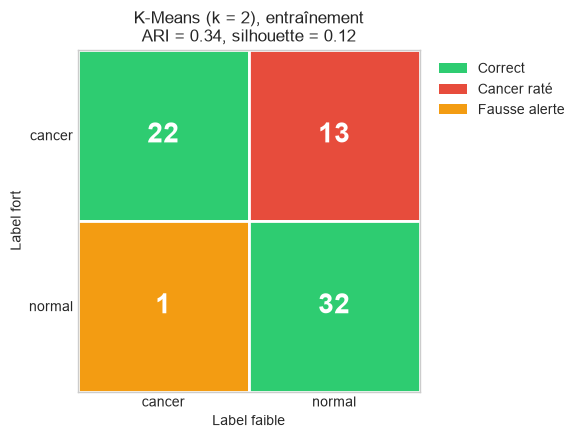

In [9]:
CONFUSION_COLORS = (
    ("#2ecc71", "#e74c3c", "#BDBDBD"),
    ("#f39c12", "#2ecc71", "#BDBDBD"),
)
CONFUSION_LEGEND = [
    Patch(facecolor="#2ecc71", label="Correct"),
    Patch(facecolor="#e74c3c", label="Cancer raté"),
    Patch(facecolor="#f39c12", label="Fausse alerte"),
    Patch(facecolor="#BDBDBD", label="Sans classe"),
]


def count_matrix(expected, predicted, unassigned=False):
    """Effectifs : lignes = label fort, colonnes = label faible (-1 : sans classe)."""
    columns = (1, 0, -1) if unassigned else (1, 0)
    return np.array(
        [
            [
                np.sum((expected == true) & (predicted == column))
                for column in columns
            ]
            for true in (1, 0)
        ]
    )


def plot_confusion(axis, matrix, title):
    """Matrice de confusion colorée : vert correct, rouge cancer raté, orange fausse alerte."""
    for row, column in np.ndindex(matrix.shape):
        axis.add_patch(
            plt.Rectangle(
                (column - 0.5, row - 0.5),
                1,
                1,
                facecolor=CONFUSION_COLORS[row][column],
                edgecolor="white",
                linewidth=2,
            )
        )
        axis.text(
            column,
            row,
            matrix[row, column],
            ha="center",
            va="center",
            fontsize=20,
            fontweight="bold",
            color="white",
        )
    axis.set(
        xlim=(-0.5, matrix.shape[1] - 0.5),
        ylim=(1.5, -0.5),
        xticks=range(matrix.shape[1]),
        yticks=[0, 1],
        xticklabels=["cancer", "normal", "sans classe"][: matrix.shape[1]],
        yticklabels=["cancer", "normal"],
        xlabel="Label faible",
        ylabel="Label fort",
        title=title,
    )
    axis.set_aspect("equal")
    axis.grid(False)


expected = train_strong[train_labeled].astype(int)
predicted = to_weak_labels(kmeans_run["labels"][train_labeled], mapping).astype(
    int
)
figure_kmeans_confusion, axis = plt.subplots(figsize=(5.5, 5))
plot_confusion(
    axis,
    count_matrix(expected, predicted),
    f"K-Means (k = 2), entraînement\nARI = {kmeans_run['ARI hors bruit']:.2f}, "
    f"silhouette = {kmeans_run['silhouette']:.2f}",
)
axis.legend(
    handles=CONFUSION_LEGEND[:3], loc="upper left", bbox_to_anchor=(1.02, 1)
)
plt.tight_layout()
figure_kmeans_confusion.savefig(
    FIGURES_DIR / "matrice-confusion-kmeans.png", dpi=120, bbox_inches="tight"
)
plt.show()

with resume_run(kmeans_run["run_id"]):
    log_figure(figure_kmeans_confusion, "matrice-confusion-kmeans.png")

Sur les 68 annotées de l'entraînement, K-Means rate **13 `cancer` sur 35** (rappel de 0,63) et prend **1 `normal` sur 33** pour un `cancer`. Cette mesure est optimiste : le vote a utilisé ces mêmes images.

### Les clusters de K-Means recoupent-ils les labels forts ?

On projette sur les deux premières composantes de la PCA les clusters de K-Means (à gauche) et les labels forts des images annotées de l'entraînement (à droite), les images non annotées restant en gris. Les croix noires marquent les **centres** des deux clusters, projetés sur les mêmes axes : en dimension 50, deux points proches sur ce plan peuvent être éloignés dans l'espace complet, et la frontière entre clusters n'est pas visible en 2D.

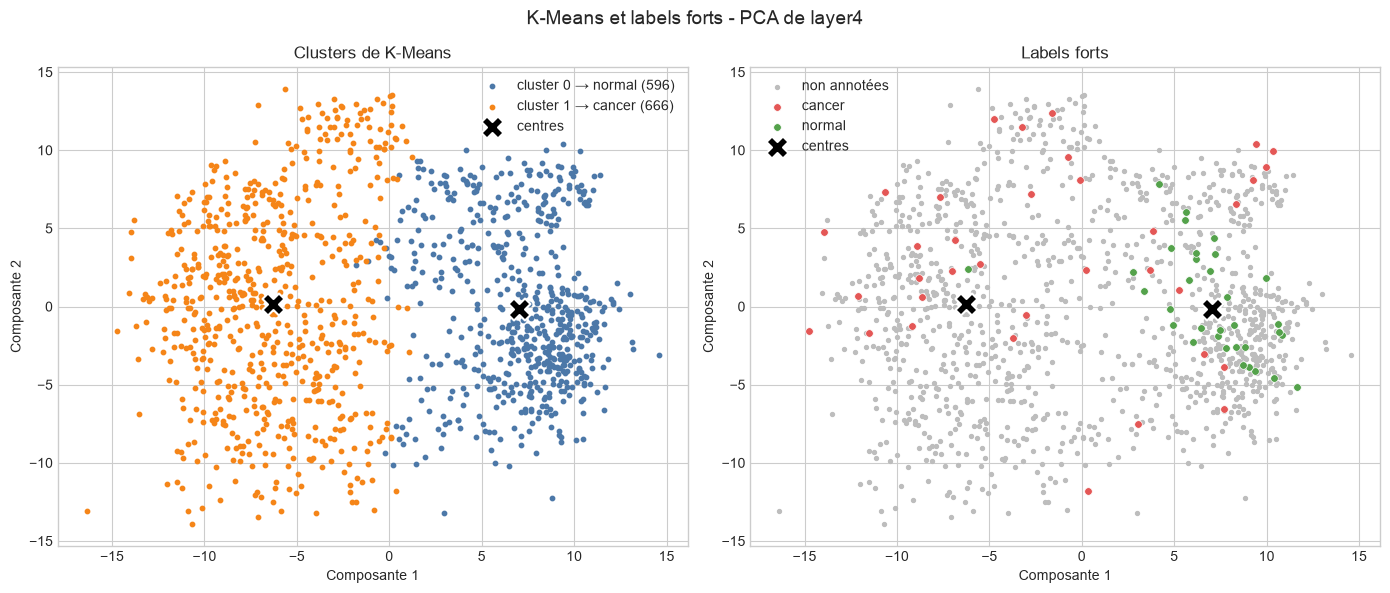

In [10]:
CLASS_NAMES = {1: "cancer", 0: "normal"}
KMEANS_COLORS = ["#4C78A8", "#F58518"]

coordinates = train_reduced[REFERENCE_LAYER][:, :2]
centers = kmeans_run["model"].cluster_centers_[:, :2]

figure, axes = plt.subplots(1, 2, figsize=(14, 6))

for cluster, color in zip(sorted(mapping), KMEANS_COLORS, strict=True):
    mask = kmeans_run["labels"] == cluster
    axes[0].scatter(
        coordinates[mask, 0],
        coordinates[mask, 1],
        s=10,
        color=color,
        label=(
            f"cluster {cluster} → {CLASS_NAMES[mapping[cluster]]} "
            f"({mask.sum()})"
        ),
    )
axes[0].set_title("Clusters de K-Means")

scatter_labels(
    axes[1], coordinates, "Labels forts", "Composante 1", "Composante 2"
)

for axis in axes:
    axis.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="X",
        s=250,
        color="black",
        edgecolor="white",
        linewidth=1.5,
        label="centres",
        zorder=3,
    )
    axis.set(xlabel="Composante 1", ylabel="Composante 2")
    axis.legend()

figure.suptitle(
    f"K-Means et labels forts - PCA de {REFERENCE_LAYER}", fontsize=14
)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "kmeans-clusters-labels.png", dpi=120, bbox_inches="tight"
)
plt.show()

## 6. Seuil de décision pour mieux repérer les cancers

En contexte médical, **rater un cancer est plus grave qu'une fausse alerte**. La règle de K-Means donne à chaque image le cluster du centre le plus proche. On peut la rendre plus prudente avec un **seuil** : pour chaque image, on calcule le rapport `d_cancer / (d_cancer + d_normal)` entre sa distance au centre `cancer` et la somme de ses distances aux deux centres. Ce rapport vaut 0,5 à égale distance des deux centres, et la règle de K-Means revient à étiqueter `cancer` quand il est **inférieur à 0,5**. Relever le seuil étiquette `cancer` davantage d'images.

Cette étape n'est plus du clustering pur : c'est une règle simple ajoutée après coup. Pour qu'elle ne profite pas du test, le seuil est **choisi sur les images annotées de l'entraînement** : on garde celui qui maximise le rappel de `cancer` en acceptant au plus **20 % de `normal` étiquetées `cancer`**. La validation vérifie ce choix ; le test n'est pas utilisé ici.

Seuil retenu sur l'entraînement : 0.53


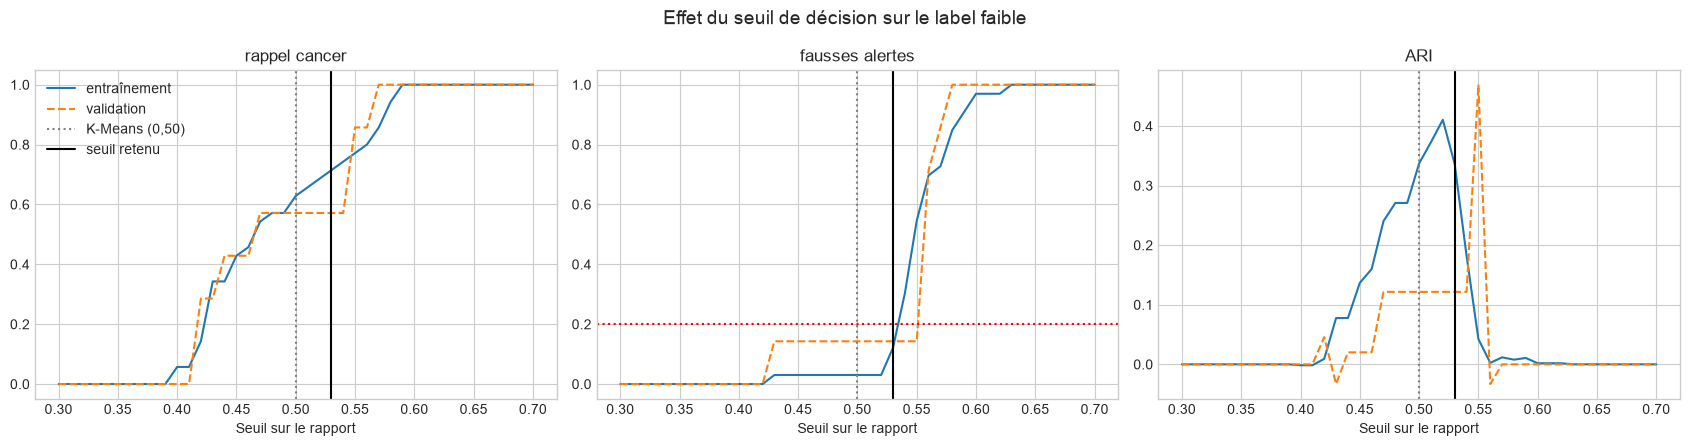

rappel cancer  fausses alertes  FN  FP  exactitude  \
jeu                                                                           
entraînement seuil 0,50          0.629            0.030  13   1       0.794   
             seuil 0.53          0.714            0.121  10   4       0.794   
validation   seuil 0,50          0.571            0.143   3   1       0.714   
             seuil 0.53          0.571            0.143   3   1       0.714   

                           ARI  
jeu                             
entraînement seuil 0,50  0.337  
             seuil 0.53  0.336  
validation   seuil 0,50  0.122  
             seuil 0.53  0.122

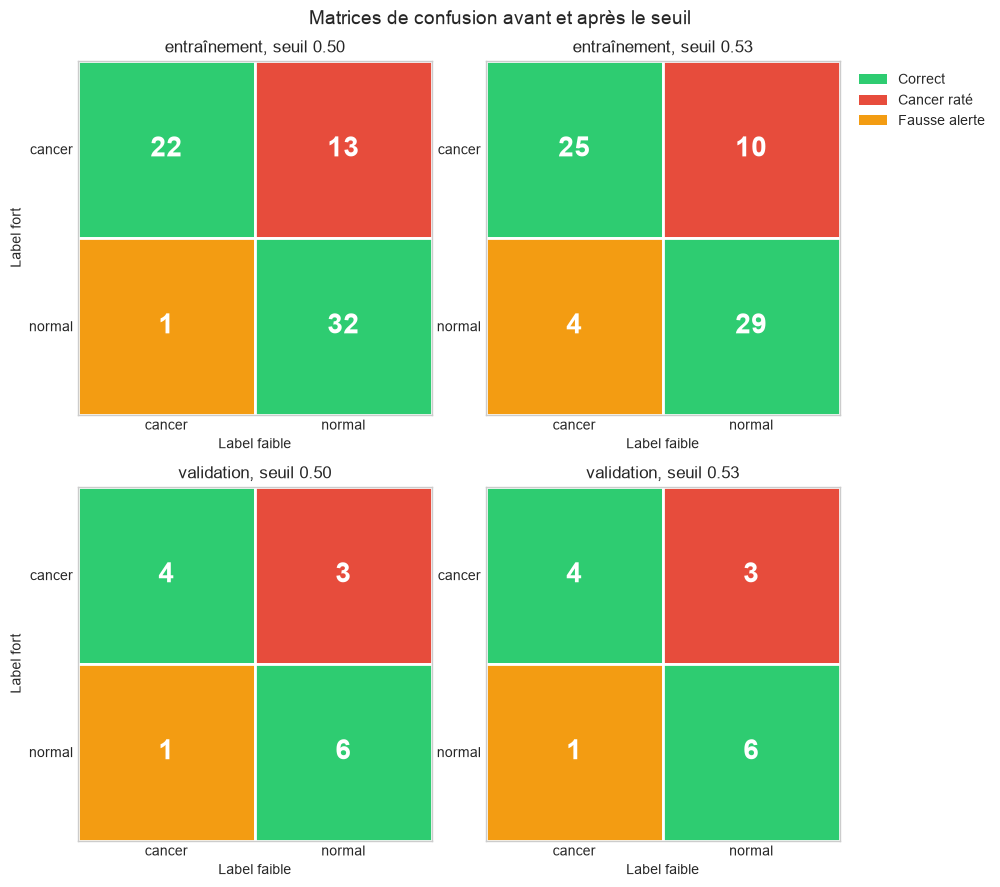

In [11]:
MAX_FALSE_ALARM = 0.20
THRESHOLDS = np.arange(0.30, 0.701, 0.01)

cluster_of_class = {
    class_code: cluster for cluster, class_code in mapping.items()
}
distances = kmeans_run["model"].transform(reduced[REFERENCE_LAYER])
cancer_distance = distances[:, cluster_of_class[1]]
normal_distance = distances[:, cluster_of_class[0]]
cancer_ratio = cancer_distance / (cancer_distance + normal_distance)


def threshold_scores(mask, threshold):
    """Mesures de la règle `rapport < seuil` sur les images annotées de `mask`."""
    expected = strong_label[mask].astype(int)
    predicted = (cancer_ratio[mask] < threshold).astype(int)
    cancers, normals = expected == 1, expected == 0
    return {
        "seuil": threshold,
        "rappel cancer": (predicted[cancers] == 1).mean(),
        "fausses alertes": (predicted[normals] == 1).mean(),
        "FN": int((predicted[cancers] == 0).sum()),
        "FP": int((predicted[normals] == 1).sum()),
        "exactitude": (predicted == expected).mean(),
        "ARI": adjusted_rand_score(expected, predicted),
    }


split_masks = {
    "entraînement": is_train & is_labeled,
    "validation": is_validation,
}
sweeps = {
    name: pd.DataFrame(
        [threshold_scores(mask, threshold) for threshold in THRESHOLDS]
    )
    for name, mask in split_masks.items()
}

allowed = sweeps["entraînement"][
    sweeps["entraînement"]["fausses alertes"] <= MAX_FALSE_ALARM
]
best = allowed[allowed["rappel cancer"] == allowed["rappel cancer"].max()]
BEST_THRESHOLD = float(best["seuil"].iloc[0])
print(f"Seuil retenu sur l'entraînement : {BEST_THRESHOLD:.2f}")

figure_threshold, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for axis, column in zip(
    axes, ("rappel cancer", "fausses alertes", "ARI"), strict=True
):
    for name, style in (("entraînement", "-"), ("validation", "--")):
        axis.plot(
            sweeps[name]["seuil"], sweeps[name][column], style, label=name
        )
    axis.axvline(0.5, color="grey", linestyle=":", label="K-Means (0,50)")
    axis.axvline(BEST_THRESHOLD, color="black", label="seuil retenu")
    axis.set(title=column, xlabel="Seuil sur le rapport")
axes[1].axhline(MAX_FALSE_ALARM, color="red", linestyle=":")
axes[0].legend()
figure_threshold.suptitle(
    "Effet du seuil de décision sur le label faible", fontsize=14
)
plt.tight_layout()
figure_threshold.savefig(
    FIGURES_DIR / "seuil-decision.png", dpi=120, bbox_inches="tight"
)
plt.show()

comparison_threshold = pd.concat(
    {
        name: pd.DataFrame(
            [
                threshold_scores(mask, 0.5),
                threshold_scores(mask, BEST_THRESHOLD),
            ],
            index=["seuil 0,50", f"seuil {BEST_THRESHOLD:.2f}"],
        ).drop(columns="seuil")
        for name, mask in split_masks.items()
    },
    names=["jeu"],
)
display(comparison_threshold.round(3))

figure_threshold_confusion, axes = plt.subplots(2, 2, figsize=(10, 9))
for row, (name, mask) in zip(axes, split_masks.items(), strict=True):
    expected = strong_label[mask].astype(int)
    for axis, threshold in zip(row, (0.5, BEST_THRESHOLD), strict=True):
        predicted = (cancer_ratio[mask] < threshold).astype(int)
        plot_confusion(
            axis,
            count_matrix(expected, predicted),
            f"{name}, seuil {threshold:.2f}",
        )
for axis in axes[:, 1]:
    axis.set_ylabel("")
axes[0, 1].legend(
    handles=CONFUSION_LEGEND[:3], loc="upper left", bbox_to_anchor=(1.02, 1)
)
figure_threshold_confusion.suptitle(
    "Matrices de confusion avant et après le seuil", fontsize=14
)
plt.tight_layout()
figure_threshold_confusion.savefig(
    FIGURES_DIR / "matrices-confusion-seuil.png", dpi=120, bbox_inches="tight"
)
plt.show()

with start_run(
    f"kmeans-{REFERENCE_LAYER}-k2-threshold{BEST_THRESHOLD:.2f}",
    phase="unsupervised",
    notebook=NOTEBOOK,
    manifest_path=MANIFEST_PATH,
    seed=RANDOM_STATE,
    description="Règle de décision de K-Means avec un seuil plus prudent",
):
    log_params(
        {
            "layer": REFERENCE_LAYER,
            "method": "K-Means",
            "k": 2,
            "n_components": N_COMPONENTS,
            "threshold": BEST_THRESHOLD,
            "max_false_alarm": MAX_FALSE_ALARM,
        }
    )
    log_dataset(
        train_table,
        name="train",
        context="training",
        source="data/interim/manifest.csv",
        targets="label",
    )
    log_metrics(
        {
            f"{key}_{metric}": comparison_threshold.loc[
                (name, f"seuil {BEST_THRESHOLD:.2f}"), column
            ]
            for name, key in (
                ("entraînement", "train"),
                ("validation", "validation"),
            )
            for metric, column in (
                ("recall_cancer", "rappel cancer"),
                ("false_alarm", "fausses alertes"),
                ("accuracy", "exactitude"),
                ("ari", "ARI"),
            )
        }
    )
    log_figure(figure_threshold, "seuil-decision.png")
    log_figure(figure_threshold_confusion, "matrices-confusion-seuil.png")

Sur l'entraînement, le seuil retenu (0,53) fait passer le rappel de `cancer` de 0,63 à 0,71, au prix de fausses alertes (de 3 % à 12 %), et l'exactitude reste à 0,79. Ce gain **ne se confirme pas sur des images jamais vues** : sur la validation, rien ne change (rappel de 0,57, fausses alertes de 14 %, exactitude de 0,71). Sur l'entraînement, les cancers ratés passent de 13 à 10 et les fausses alertes de 1 à 4 ; sur la validation, 3 cancers restent ratés et une fausse alerte reste. Un seuil choisi sur 68 images s'ajuste à elles : on garde la règle de K-Means, au seuil de 0,50.

## 7. Nombre de clusters

Le jeu annoté compte deux classes, mais rien n'oblige les images à former deux groupes. On fait varier `k` de 2 à 6 et on mesure :

- l'**inertie** : somme des carrés des distances aux centres, qui baisse toujours quand `k` augmente (on cherche un coude) ;
- le **score de silhouette** des clusters, dans l'espace PCA ;
- l'**ARI** avec les labels forts ;
- la **pureté** : part des images annotées de la classe majoritaire de leur cluster, qui monte mécaniquement avec `k`.

Les valeurs de `k` autres que 2 sont aussi des runs MLflow, mais ne servent pas à la suite.

ARI     inertia  silhouette  purity
couche k                                       
layer3 2  0.092  232959.438       0.152   0.662
       3  0.052  206970.625       0.167   0.647
       4  0.133  188956.625       0.168   0.721
       5  0.144  178492.938       0.173   0.779
       6  0.086  169303.156       0.164   0.765
layer4 2  0.337  414241.312       0.122   0.794
       3  0.357  387224.250       0.120   0.824
       4  0.250  363112.969       0.118   0.809
       5  0.213  345865.281       0.121   0.794
       6  0.253  333444.469       0.118   0.838

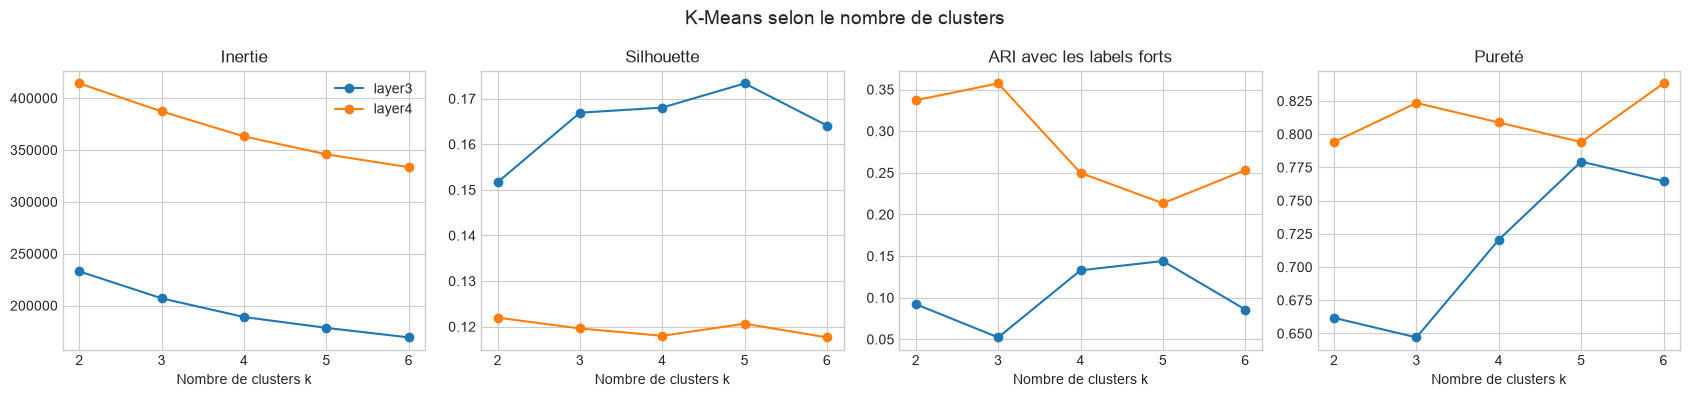

In [12]:
K_VALUES = range(2, 7)

sweep_rows = []
sweep_labels = {}
for layer in EXTRACTION_LAYERS:
    for k in K_VALUES:
        model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        model.fit(train_reduced[layer])
        sweep_labels[layer, k] = model.labels_
        scores = {
            "inertia": model.inertia_,
            "silhouette": silhouette_score(train_reduced[layer], model.labels_),
            "purity": purity(model.labels_, train_strong),
        }
        if k != 2:
            record(
                layer,
                "K-Means",
                {"k": k},
                model.labels_,
                keep=False,
                model=model,
                **scores,
            )
        sweep_rows.append(
            {
                "couche": layer,
                "k": k,
                "ARI": ari_without_noise(
                    model.labels_[train_labeled], train_strong[train_labeled]
                ),
                **scores,
            }
        )
sweep = pd.DataFrame(sweep_rows)
display(sweep.round(3).set_index(["couche", "k"]))

figure, axes = plt.subplots(1, 4, figsize=(17, 4))
for axis, (column, title) in zip(
    axes,
    (
        ("inertia", "Inertie"),
        ("silhouette", "Silhouette"),
        ("ARI", "ARI avec les labels forts"),
        ("purity", "Pureté"),
    ),
    strict=True,
):
    for layer, group in sweep.groupby("couche"):
        axis.plot(group["k"], group[column], marker="o", label=layer)
    axis.set(title=title, xlabel="Nombre de clusters k", xticks=list(K_VALUES))
axes[0].legend()
figure.suptitle("K-Means selon le nombre de clusters", fontsize=14)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "balayage-k.png", dpi=120, bbox_inches="tight")
plt.show()

with resume_run(kmeans_run["run_id"]):
    log_figure(figure, "balayage-k.png")

Aucun nombre de clusters ne se détache : l'inertie baisse régulièrement sans coude net, la silhouette reste voisine de 0,12 sur `layer4`, et l'ARI fluctue (0,34 pour `k = 2`, 0,36 pour `k = 3`, 0,25 pour `k = 6`). La pureté monte avec `k` : c'est mécanique, car des clusters plus petits sont plus faciles à rendre homogènes. On garde `k = 2`, qui correspond aux deux classes du jeu annoté. Sur `layer3`, l'ARI reste inférieur à 0,15 pour toutes les valeurs de `k`.

### k = 2 contre le meilleur autre k

On compare la partition en deux groupes à celle du **meilleur `k` supérieur à 2 selon l'ARI**, sur la couche de référence.

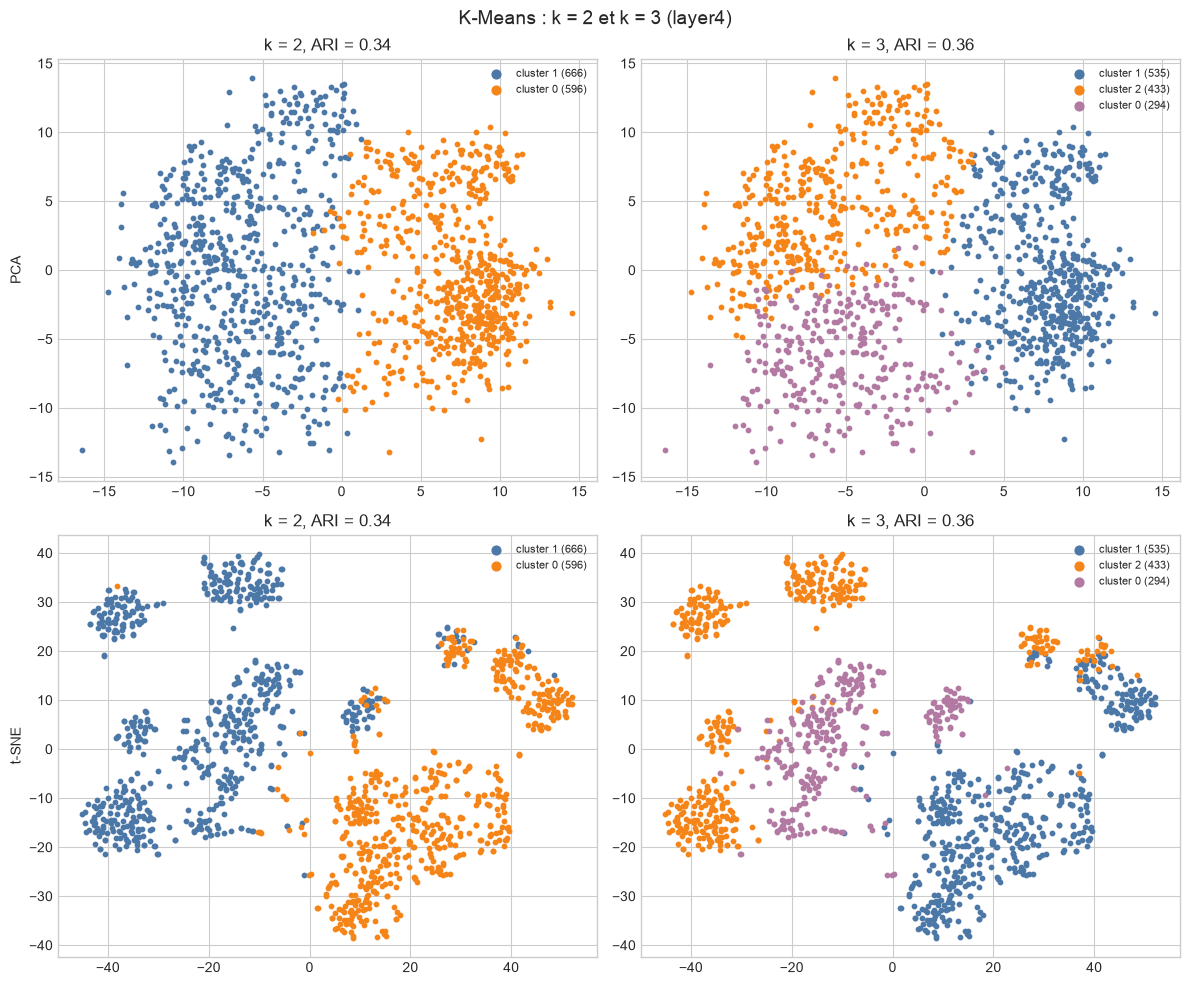

In [13]:
CLUSTER_COLORS = ["#4C78A8", "#F58518", "#B279A2", "#72B7B2", "#EECA3B"]
OTHER_COLOR = "#9D755D"
NOISE_COLOR = "#BDBDBD"


def scatter_clusters(axis, coordinates, cluster_labels, title):
    """Nuage 2D : les plus gros clusters en couleur, le bruit en gris."""
    clustered = cluster_labels[cluster_labels != -1]
    clusters, sizes = np.unique(clustered, return_counts=True)
    largest = clusters[np.argsort(-sizes)][: len(CLUSTER_COLORS)]
    groups = []
    if (cluster_labels == -1).any():
        groups.append((cluster_labels == -1, NOISE_COLOR, "bruit"))
    for cluster, color in zip(largest, CLUSTER_COLORS, strict=False):
        groups.append((cluster_labels == cluster, color, f"cluster {cluster}"))
    others = (cluster_labels != -1) & ~np.isin(cluster_labels, largest)
    if others.any():
        groups.append((others, OTHER_COLOR, "autres clusters"))
    for mask, color, name in groups:
        axis.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=10,
            color=color,
            label=f"{name} ({mask.sum()})",
        )
    axis.set_title(title)
    axis.legend(markerscale=2, fontsize=8)


best_k = int(
    sweep[(sweep["couche"] == REFERENCE_LAYER) & (sweep["k"] > 2)]
    .sort_values("ARI")
    .iloc[-1]["k"]
)
ari_by_k = sweep.set_index(["couche", "k"])["ARI"]

figure_k, axes = plt.subplots(2, 2, figsize=(12, 10))
for column, k in enumerate((2, best_k)):
    title = f"k = {k}, ARI = {ari_by_k[REFERENCE_LAYER, k]:.2f}"
    scatter_clusters(
        axes[0, column],
        train_reduced[REFERENCE_LAYER][:, :2],
        sweep_labels[REFERENCE_LAYER, k],
        title,
    )
    scatter_clusters(
        axes[1, column],
        tsne_coordinates[REFERENCE_LAYER],
        sweep_labels[REFERENCE_LAYER, k],
        title,
    )
axes[0, 0].set_ylabel("PCA")
axes[1, 0].set_ylabel("t-SNE")
figure_k.suptitle(
    f"K-Means : k = 2 et k = {best_k} ({REFERENCE_LAYER})", fontsize=14
)
plt.tight_layout()
figure_k.savefig(
    FIGURES_DIR / "k2-contre-meilleur-k.png", dpi=120, bbox_inches="tight"
)
plt.show()

Le partage en trois groupes sépare celui de gauche en deux (haut et bas de la PCA) et laisse celui de droite à peu près entier ; son ARI est de 0,36 contre 0,34. L'écart est faible, et l'ARI redescend ensuite pour `k` de 4 à 6 (0,25, 0,21 puis 0,25) : il ne justifie pas de quitter les deux classes du jeu annoté.

## 8. DBSCAN

DBSCAN regroupe les images situées dans une zone **dense** et laisse les autres de côté. Il ne demande pas le nombre de clusters, mais deux paramètres : `min_samples` (nombre de voisins requis pour qu'une image soit « dense ») et `eps` (rayon du voisinage).

Les images qu'aucun cluster n'accepte forment le **bruit** (`-1`). C'est un résultat **attendu** de la méthode, pas une anomalie : le bruit est rapporté (part des images), mais il n'est **ni un cluster, ni une classe**. L'ARI est calculé sur les images annotées qui appartiennent à un cluster (« ARI hors bruit »), avec le nombre d'images évaluées.

Pour choisir `eps`, on trace la **distance au `min_samples`-ième voisin**, triée : le « coude » sépare les images des zones denses (courbe plate) des images isolées (courbe qui monte).

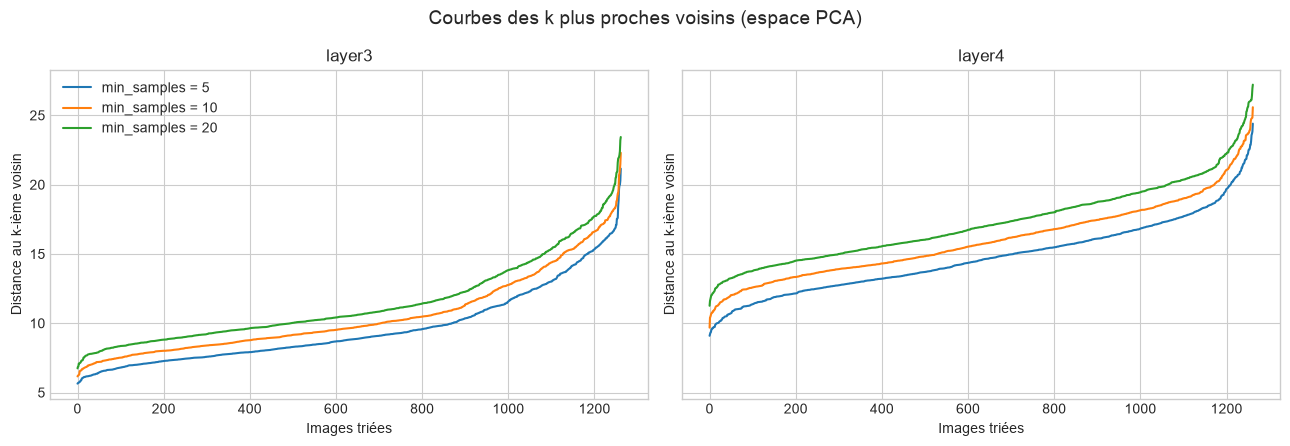

In [14]:
MIN_SAMPLES_VALUES = (5, 10, 20)

k_distances = {}
for layer in EXTRACTION_LAYERS:
    for min_samples in MIN_SAMPLES_VALUES:
        neighbors = NearestNeighbors(n_neighbors=min_samples)
        neighbors.fit(train_reduced[layer])
        distances, _ = neighbors.kneighbors(train_reduced[layer])
        k_distances[layer, min_samples] = np.sort(distances[:, -1])

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for axis, layer in zip(axes, EXTRACTION_LAYERS, strict=True):
    for min_samples in MIN_SAMPLES_VALUES:
        axis.plot(
            k_distances[layer, min_samples],
            label=f"min_samples = {min_samples}",
        )
    axis.set(
        title=layer, xlabel="Images triées", ylabel="Distance au k-ième voisin"
    )
axes[0].legend()
figure.suptitle("Courbes des k plus proches voisins (espace PCA)", fontsize=14)
plt.tight_layout()
figure.savefig(
    FIGURES_DIR / "courbes-k-distance.png", dpi=120, bbox_inches="tight"
)
plt.show()

Sur les deux couches, la courbe est presque plate puis monte nettement pour les images les plus isolées : le coude est peu marqué. On balaie donc plusieurs valeurs de `eps`, choisies comme des **quantiles** de la courbe (70 %, 80 %, 90 % et 95 % des images ont leur k-ième voisin plus proche que `eps`).

In [15]:
EPS_QUANTILES = (0.7, 0.8, 0.9, 0.95)

for layer in EXTRACTION_LAYERS:
    for min_samples in MIN_SAMPLES_VALUES:
        for quantile in EPS_QUANTILES:
            eps = float(np.quantile(k_distances[layer, min_samples], quantile))
            model = DBSCAN(eps=eps, min_samples=min_samples)
            model.fit(train_reduced[layer])
            record(
                layer,
                "DBSCAN",
                {"min_samples": min_samples, "eps": round(eps, 1)},
                model.labels_,
            )

GRID_COLUMNS = [
    "couche",
    "paramètres",
    "clusters",
    "bruit",
    "images évaluées",
    "ARI hors bruit",
]
dbscan_grid = pd.DataFrame(all_runs).query("méthode == 'DBSCAN'")
display(
    dbscan_grid[GRID_COLUMNS]
    .sort_values(["couche", "ARI hors bruit"], ascending=[True, False])
    .round(3)
    .reset_index(drop=True)
)

,couche,paramètres,clusters,bruit,images évaluées,ARI hors bruit
0,layer3,"{'min_samples': 5, 'eps': 11.8}",4,0.149,43,0.571
1,layer3,"{'min_samples': 20, 'eps': 12.1}",2,0.208,38,0.474
2,layer3,"{'min_samples': 10, 'eps': 11.0}",5,0.219,37,0.181
3,layer3,"{'min_samples': 5, 'eps': 10.2}",7,0.248,32,0.065
4,layer3,"{'min_samples': 5, 'eps': 13.7}",1,0.067,55,0.000
5,layer3,"{'min_samples': 5, 'eps': 15.3}",1,0.019,67,0.000
6,layer3,"{'min_samples': 10, 'eps': 12.9}",1,0.125,47,0.000
7,layer3,"{'min_samples': 10, 'eps': 15.2}",1,0.038,62,0.000
8,layer3,"{'min_samples': 10, 'eps': 16.6}",1,0.009,67,0.000
9,layer3,"{'min_samples': 20, 'eps': 13.9}",1,0.097,51,0.000


Sur `layer3`, deux configurations atteignent un ARI hors bruit de 0,47 et 0,57, mais sur 38 et 43 images annotées sur 68 seulement : l'ARI ne juge que les images que la méthode accepte. Sur `layer4`, une seule configuration forme plusieurs clusters (trois), les 11 autres n'en forment qu'un.

### Comparaison des méthodes

Les méthodes sont comparées sur la couche de référence, `layer4`, retenue à l'étape précédente. Pour DBSCAN, on retient la configuration de la grille qui a **au moins deux clusters**, **au plus 30 % de bruit** et le meilleur ARI hors bruit. Cette sélection sert à **illustrer** la méthode : DBSCAN suppose des zones **denses**, et le nuage de points ne l'est pas. K-Means, qui n'a pas de paramètre à choisir, reste la référence.

Le bruit de DBSCAN (les images qu'aucune zone dense n'accepte) n'a pas de cluster, donc pas de classe : la **couverture** est la part des images qui en reçoivent un. L'ARI de DBSCAN est calculé sur ces seules images, qui ne sont pas les mêmes que celles de K-Means : les deux ARI ne sont **pas strictement comparables**.

In [16]:
MAX_NOISE = 0.30

results = pd.DataFrame(all_runs)
candidates = results[
    (results["couche"] == REFERENCE_LAYER)
    & (results["méthode"] == "DBSCAN")
    & (results["clusters"] >= 2)
    & (results["bruit"] <= MAX_NOISE)
]
selected = candidates.loc[[candidates["ARI hors bruit"].idxmax()]]
reference = results[
    (results["couche"] == REFERENCE_LAYER) & (results["méthode"] == "K-Means")
]
comparison_runs = pd.concat([reference, selected]).reset_index(drop=True)
comparison_runs["couverture"] = 1 - comparison_runs["bruit"]

display(
    comparison_runs[
        [
            "méthode",
            "paramètres",
            "clusters",
            "couverture",
            "images évaluées",
            "ARI hors bruit",
        ]
    ].round(3)
)

,méthode,paramètres,clusters,couverture,images évaluées,ARI hors bruit
0,K-Means,{'k': 2},2,1.000,68,0.337
1,DBSCAN,"{'min_samples': 5, 'eps': 16.0}",3,0.836,47,0.266


Chaque méthode est représentée avec sa configuration retenue, sur la PCA (ligne du haut) et sur le t-SNE (ligne du bas) de la couche de référence. Les points gris sont du bruit.

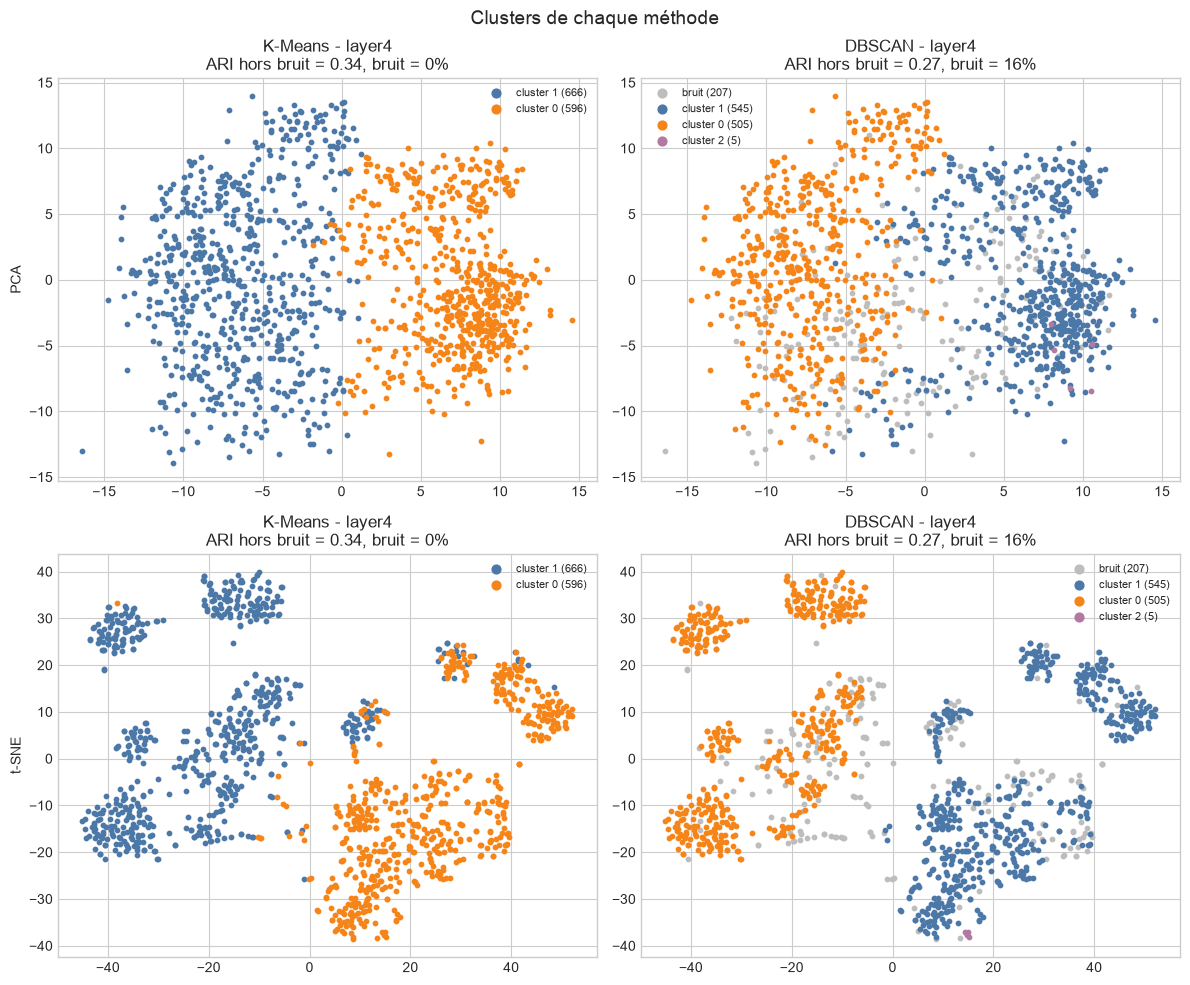

In [17]:
figure, axes = plt.subplots(
    2, len(comparison_runs), figsize=(12, 10), squeeze=False
)
for column, (_, run) in enumerate(comparison_runs.iterrows()):
    title = (
        f"{run['méthode']} - {run['couche']}\n"
        f"ARI hors bruit = {run['ARI hors bruit']:.2f}, "
        f"bruit = {run['bruit']:.0%}"
    )
    scatter_clusters(
        axes[0, column],
        train_reduced[run["couche"]][:, :2],
        run["labels"],
        title,
    )
    scatter_clusters(
        axes[1, column], tsne_coordinates[run["couche"]], run["labels"], title
    )
axes[0, 0].set_ylabel("PCA")
axes[1, 0].set_ylabel("t-SNE")
figure.suptitle("Clusters de chaque méthode", fontsize=14)
plt.tight_layout()
figure.savefig(FIGURES_DIR / "clusters-2d.png", dpi=120, bbox_inches="tight")
plt.show()

### Matrices de confusion

Sur les images annotées de l'entraînement, chaque cluster de DBSCAN reçoit la classe majoritaire de ses images annotées, comme pour K-Means. Le bruit et les clusters sans image annotée n'ont pas de classe : ils forment une colonne **sans classe**, qui n'existe pas pour K-Means.

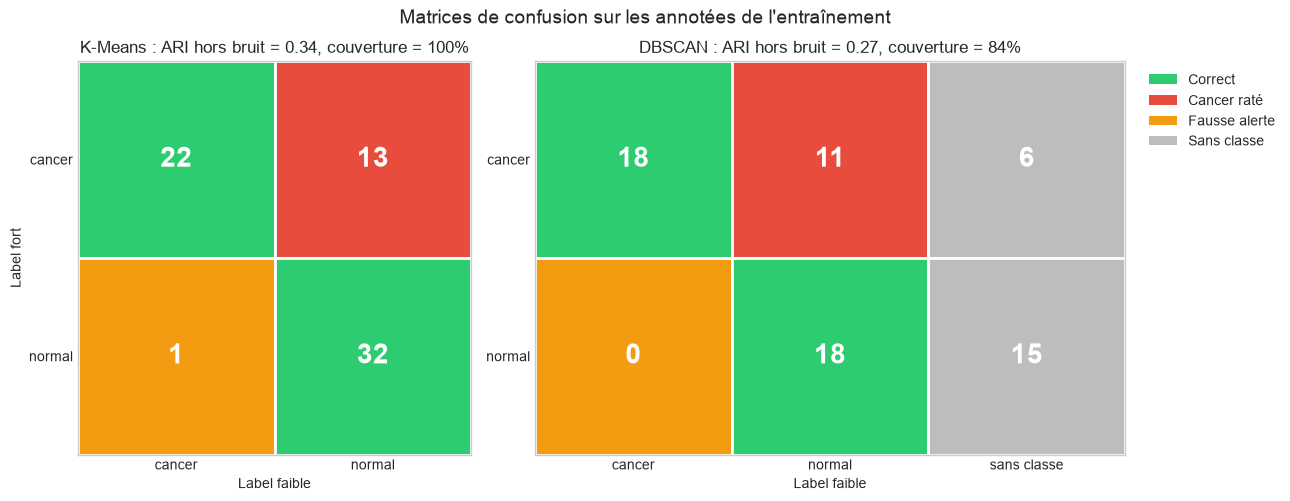

In [18]:
figure_methods, axes = plt.subplots(
    1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [2, 3]}
)
expected = train_strong[train_labeled].astype(int)
for axis, (_, run) in zip(axes, comparison_runs.iterrows(), strict=True):
    run_mapping = majority_mapping(run["labels"], train_strong, train_labeled)
    predicted = np.nan_to_num(
        to_weak_labels(run["labels"][train_labeled], run_mapping), nan=-1
    ).astype(int)
    plot_confusion(
        axis,
        count_matrix(expected, predicted, unassigned=(predicted == -1).any()),
        f"{run['méthode']} : ARI hors bruit = {run['ARI hors bruit']:.2f}, "
        f"couverture = {run['couverture']:.0%}",
    )
axes[1].set_ylabel("")
axes[1].legend(
    handles=CONFUSION_LEGEND, loc="upper left", bbox_to_anchor=(1.02, 1)
)
figure_methods.suptitle(
    "Matrices de confusion sur les annotées de l'entraînement", fontsize=14
)
plt.tight_layout()
figure_methods.savefig(
    FIGURES_DIR / "matrices-confusion-methodes.png",
    dpi=120,
    bbox_inches="tight",
)
plt.show()

Sur les mêmes images, DBSCAN rate **11 `cancer` sur 35** et laisse **21 images sans classe** (6 `cancer`, 15 `normal`), contre 13 `cancer` ratés et aucune image sans classe pour K-Means. Son ARI (0,27) reste inférieur à celui de K-Means (0,34), alors qu'il écarte ces images.

### Choix de la méthode

**K-Means** (couche `layer4`, 50 composantes, `k = 2`) est retenu, pour trois raisons :

1. il attribue une classe à **toutes** les images, alors que DBSCAN laisse des images sans cluster, donc sans classe ;
2. il produit directement **deux groupes**, comme les deux classes du jeu annoté ;
3. il est **stable** : même ARI (0,337) pour 10, 20 et 50 composantes comme pour les features complètes, et même résultat pour 10 seeds.

Seul K-Means fournit donc des labels faibles. DBSCAN reste dans le notebook à titre de comparaison.

## 9. Labels faibles

Le vote de la section 5 associe chaque cluster à une classe. On l'applique à toutes les images **non annotées** de l'entraînement : chacune reçoit le label faible de son cluster. Pour mesurer la fiabilité d'une attribution, on calcule une **confiance** : la marge relative entre la distance au centre le plus proche et la distance à l'autre centre (0 = à égale distance des deux centres, 1 = sur le centre).

Le vote, la confiance et la construction des labels faibles sont implémentés dans `brain_mri.modeling.unsupervised`. Les labels faibles des images **non annotées** sont exportés dans `data/processed/weak_labels.csv`, un fichier séparé du jeu annoté.

In [19]:
train_manifest = manifest[is_train].reset_index(drop=True)
train_weak = to_weak_labels(kmeans_run["labels"], mapping)
weak_labels = build_weak_labels(
    train_manifest,
    kmeans_run["labels"],
    mapping,
    kmeans_confidence(kmeans_run["model"], train_reduced[REFERENCE_LAYER]),
)
weak_labels.to_csv(PROCESSED_DATA_DIR / "weak_labels.csv", index=False)

assert len(weak_labels) == (~manifest["is_labeled"]).sum()
assert weak_labels["weak_label"].notna().all()
display(weak_labels["weak_label"].value_counts().rename("images").to_frame())

,images
weak_label,
cancer,643
normal,551


### Confiance des labels faibles

On range les labels faibles en trois tranches de confiance : **indécise** (moins de 0,10), **hésitante** (de 0,10 à 0,20) et **confiante** (0,20 et plus). Ces seuils sont **descriptifs** : ils servent à trier les images, pas à en écarter.

tranche,indécise,hésitante,confiante
weak_label,,,
cancer,243,392,8
normal,185,296,70


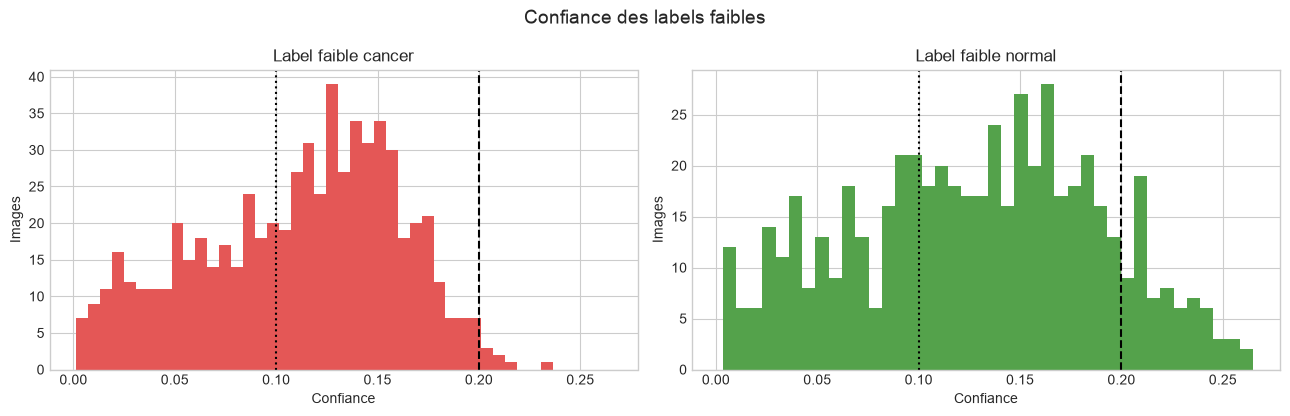

In [20]:
UNDECIDED, CONFIDENT = 0.10, 0.20

weak_labels["tranche"] = pd.cut(
    weak_labels["confidence"],
    [-np.inf, UNDECIDED, CONFIDENT, np.inf],
    labels=["indécise", "hésitante", "confiante"],
    right=False,
)
display(pd.crosstab(weak_labels["weak_label"], weak_labels["tranche"]))

figure_confidence, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for axis, (_, name, color) in zip(axes, LABEL_COLORS, strict=True):
    axis.hist(
        weak_labels.loc[weak_labels["weak_label"] == name, "confidence"],
        bins=40,
        color=color,
    )
    axis.axvline(UNDECIDED, color="black", linestyle=":")
    axis.axvline(CONFIDENT, color="black", linestyle="--")
    axis.set(
        title=f"Label faible {name}",
        xlabel="Confiance",
        ylabel="Images",
    )
figure_confidence.suptitle("Confiance des labels faibles", fontsize=14)
plt.tight_layout()
figure_confidence.savefig(
    FIGURES_DIR / "confiance-labels-faibles.png", dpi=120, bbox_inches="tight"
)
plt.show()

Seuls **78 labels faibles sur 1 194 (6,5 %)** sont confiants, contre 428 indécis (35,8 %) et 688 hésitants (57,6 %). Les labels faibles `normal` sont plus de dix fois plus souvent confiants que les `cancer` (70 sur 551, soit 13 %, contre 8 sur 643, soit 1 %). La plupart des images sont donc proches de la frontière entre les deux clusters.

### Images les plus confiantes

Les images les plus confiantes de chaque label faible permettent de juger si le regroupement est cohérent à l'œil. La confiance est indiquée au-dessus de chaque image.

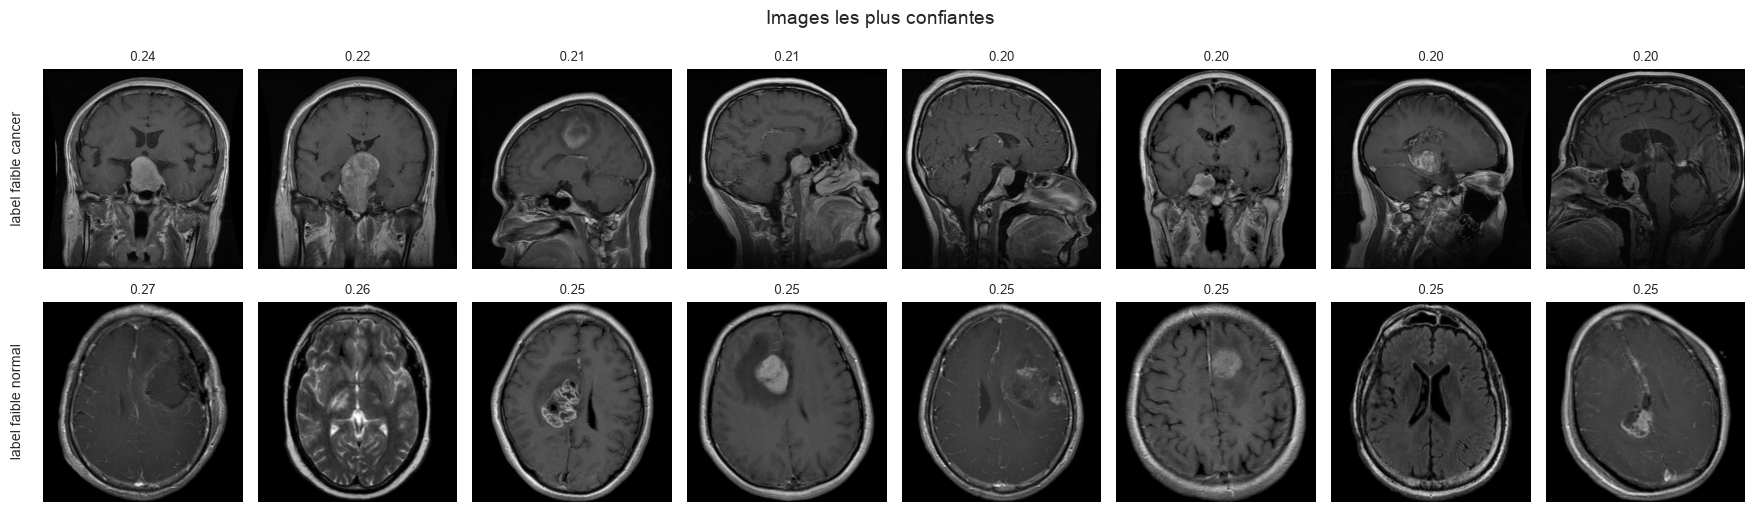

In [21]:
TOP_IMAGES = 8

by_id = manifest.set_index("image_id")
by_confidence = weak_labels.sort_values("confidence", ascending=False)

figure_top, axes = plt.subplots(2, TOP_IMAGES, figsize=(2.2 * TOP_IMAGES, 5.4))
for row, (_, name, _) in zip(axes, LABEL_COLORS, strict=True):
    top = by_confidence[by_confidence["weak_label"] == name].head(TOP_IMAGES)
    for axis, (_, image) in zip(row, top.iterrows(), strict=True):
        with Image.open(by_id.loc[image["image_id"], "filepath"]) as picture:
            axis.imshow(picture.convert("L"), cmap="gray")
        axis.set_title(f"{image['confidence']:.2f}", fontsize=9)
        axis.axis("off")
    row[0].text(
        -0.1,
        0.5,
        f"label faible {name}",
        transform=row[0].transAxes,
        rotation=90,
        va="center",
        ha="right",
    )
figure_top.suptitle("Images les plus confiantes", fontsize=14)
plt.tight_layout()
figure_top.savefig(
    FIGURES_DIR / "images-confiantes.png", dpi=120, bbox_inches="tight"
)
plt.show()

Les images les plus confiantes du label faible `cancer` sont des coupes coronales ou sagittales, celles du label `normal` des coupes axiales. Plusieurs images du label `normal` montrent pourtant une masse visible : la confiance mesure la **proximité du centre**, pas l'absence de tumeur. Le regroupement semble suivre le plan de coupe autant que la pathologie.

### Où tombent les labels faibles

Sur la PCA et le t-SNE de l'entraînement, les images non annotées sont colorées par leur **label faible** (points pâles) et les images annotées par leur **label fort** (points cerclés de noir). Un label faible situé au milieu d'images annotées de l'autre classe signale un cas douteux.

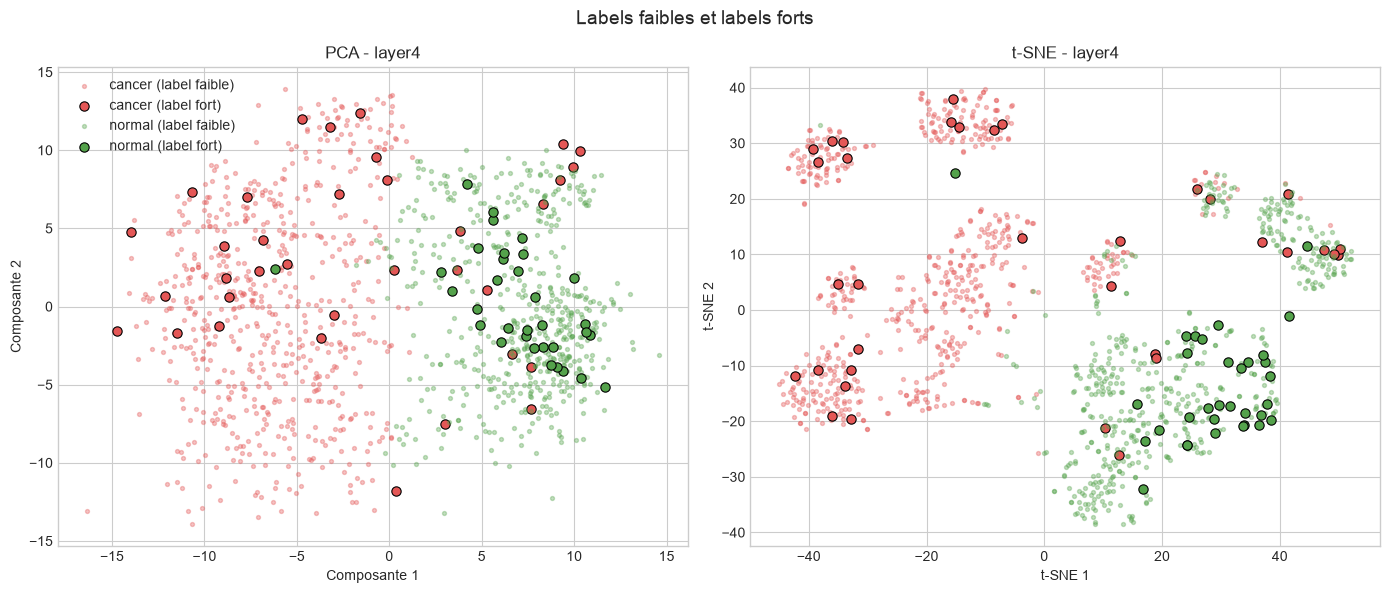

In [22]:
unlabeled = ~train_labeled
weak_code = (weak_labels["weak_label"] == "cancer").to_numpy().astype(int)
if len(weak_code) != unlabeled.sum():
    raise ValueError("Un label faible par image non annotée est attendu.")

figure_weak, axes = plt.subplots(1, 2, figsize=(14, 6))
for axis, coordinates, title, xlabel, ylabel in (
    (
        axes[0],
        train_reduced[REFERENCE_LAYER][:, :2],
        f"PCA - {REFERENCE_LAYER}",
        "Composante 1",
        "Composante 2",
    ),
    (
        axes[1],
        tsne_coordinates[REFERENCE_LAYER],
        f"t-SNE - {REFERENCE_LAYER}",
        "t-SNE 1",
        "t-SNE 2",
    ),
):
    for value, name, color in LABEL_COLORS:
        axis.scatter(
            coordinates[unlabeled][weak_code == value, 0],
            coordinates[unlabeled][weak_code == value, 1],
            s=8,
            color=color,
            alpha=0.35,
            label=f"{name} (label faible)",
        )
        strong = train_labeled & (train_strong == value)
        axis.scatter(
            coordinates[strong, 0],
            coordinates[strong, 1],
            s=45,
            color=color,
            edgecolor="black",
            linewidth=0.8,
            label=f"{name} (label fort)",
        )
    axis.set(title=title, xlabel=xlabel, ylabel=ylabel)
axes[0].legend()
figure_weak.suptitle("Labels faibles et labels forts", fontsize=14)
plt.tight_layout()
figure_weak.savefig(
    FIGURES_DIR / "labels-faibles-2d.png", dpi=120, bbox_inches="tight"
)
plt.show()

with resume_run(kmeans_run["run_id"]):
    log_figure(figure_confidence, "confiance-labels-faibles.png")
    log_figure(figure_top, "images-confiantes.png")
    log_figure(figure_weak, "labels-faibles-2d.png")

Sur la PCA, la frontière entre labels faibles se situe entre 0 et 3 sur la composante 1. Sur le t-SNE, chaque îlot reçoit un seul label faible. Des images annotées `cancer` se trouvent dans la zone des labels faibles `normal` (et inversement) : ce sont les erreurs étudiées plus bas.

## 10. Évaluation sur la validation et le test

Le test n'a servi à rien jusqu'ici, et la validation seulement à vérifier le seuil de décision. K-Means les rattache au centre le plus proche (`predict`), avec les mêmes règles que pour l'entraînement. On mesure l'ARI et l'**exactitude du label faible** : la part de labels faibles égaux au label fort. Sur l'entraînement, cette exactitude est **optimiste**, car le vote a utilisé ces mêmes images. Avec 14 images de validation et 15 de test, une image représente plusieurs points d'exactitude : ces mesures sont indicatives.

In [23]:
def assign_clusters(run, mask):
    """Clusters des images de `mask` : le centre le plus proche (`predict`)."""
    return run["model"].predict(reduced[run["couche"]][mask])


display(
    pd.DataFrame(
        [
            {
                "jeu": split_name,
                "ARI": ari_without_noise(
                    assign_clusters(kmeans_run, mask), strong_label[mask]
                ),
            }
            for split_name, mask in (
                ("validation", is_validation),
                ("test", is_test),
            )
        ]
    )
    .set_index("jeu")
    .round(3)
)

kmeans_clusters = {
    "entraînement (optimiste)": kmeans_run["labels"][train_labeled],
    "validation": assign_clusters(kmeans_run, is_validation),
    "test": assign_clusters(kmeans_run, is_test),
}
true_labels = {
    "entraînement (optimiste)": train_strong[train_labeled],
    "validation": strong_label[is_validation],
    "test": strong_label[is_test],
}
display(
    pd.DataFrame(
        {
            split_name: {
                "images": len(clusters),
                "exactitude du label faible": (
                    to_weak_labels(clusters, mapping) == true_labels[split_name]
                ).mean(),
            }
            for split_name, clusters in kmeans_clusters.items()
        }
    ).T.round(3)
)

,ARI
jeu,
validation,0.122
test,0.504


,images,exactitude du label faible
entraînement (optimiste),68.0,0.794
validation,14.0,0.714
test,15.0,0.867


### Quelles erreurs fait le label faible ?

L'exactitude ne dit pas quelle classe est mal étiquetée. On détaille donc les erreurs de K-Means sur la validation et le test :

- la **matrice de confusion** compte, pour chaque label fort, les labels faibles attribués ;
- la **précision** d'une classe est la part des images étiquetées dans cette classe qui y appartiennent vraiment ;
- le **rappel** d'une classe est la part des images de cette classe qui ont reçu le bon label faible. En contexte médical, le rappel de `cancer` compte : un cancer étiqueté `normal` est l'erreur la plus grave ;
- le **F1** est la moyenne harmonique de la précision et du rappel ;
- l'**exactitude équilibrée** est la moyenne des rappels des deux classes ;
- l'**intervalle de confiance à 95 %** de l'exactitude (méthode de Wilson) traduit l'incertitude due au petit nombre d'images.

Avec 14 et 15 images, ces mesures restent indicatives. Elles sont calculées par `evaluate_weak_labels` (`brain_mri.modeling.unsupervised`).

In [24]:
confusion_tables = {}
class_tables = {}
summary_rows = []
for split_name, mask in (("validation", is_validation), ("test", is_test)):
    expected = strong_label[mask].astype(int)
    predicted = to_weak_labels(
        assign_clusters(kmeans_run, mask), mapping
    ).astype(int)
    evaluation = evaluate_weak_labels(expected, predicted)
    confusion_tables[split_name] = evaluation.confusion
    class_tables[split_name] = evaluation.per_class
    summary_rows.append({"jeu": split_name, **evaluation.summary})

display(pd.concat(class_tables, names=["jeu"]).round(3))
display(pd.DataFrame(summary_rows).set_index("jeu").round(3))

précision  rappel     F1  images
jeu        classe                                  
validation cancer      0.800   0.571  0.667       7
           normal      0.667   0.857  0.750       7
test       cancer      1.000   0.750  0.857       8
           normal      0.778   1.000  0.875       7

,images,exactitude,IC 95 % bas,IC 95 % haut,exactitude équilibrée
jeu,,,,,
validation,14,0.714,0.454,0.883,0.714
test,15,0.867,0.621,0.963,0.875


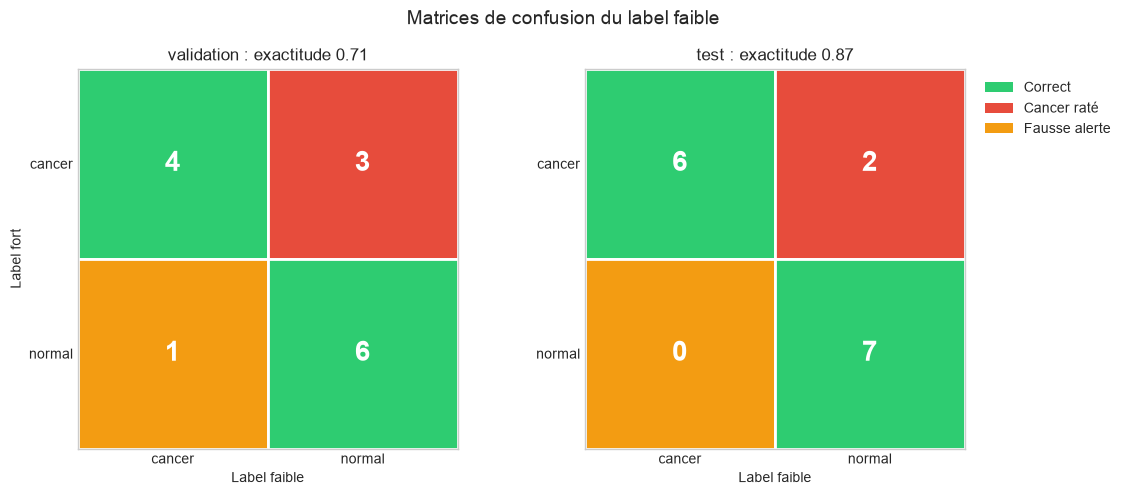

In [25]:
figure_confusion, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, (split_name, mask) in zip(
    axes, (("validation", is_validation), ("test", is_test)), strict=True
):
    expected = strong_label[mask].astype(int)
    predicted = to_weak_labels(
        assign_clusters(kmeans_run, mask), mapping
    ).astype(int)
    plot_confusion(
        axis,
        count_matrix(expected, predicted),
        f"{split_name} : exactitude {(expected == predicted).mean():.2f}",
    )
axes[1].set_ylabel("")
axes[1].legend(
    handles=CONFUSION_LEGEND[:3], loc="upper left", bbox_to_anchor=(1.02, 1)
)
figure_confusion.suptitle("Matrices de confusion du label faible", fontsize=14)
plt.tight_layout()
figure_confusion.savefig(
    FIGURES_DIR / "matrices-confusion-labels-faibles.png",
    dpi=120,
    bbox_inches="tight",
)
plt.show()

### Où le label faible se trompe-t-il ?

On réunit les images annotées (entraînement, validation et test) avec leur label fort et leur label faible. Sur la PCA et sur le t-SNE, les images **bien étiquetées sont grisées** et les **erreurs** portent une croix épaisse au premier plan : **rouge** pour la validation et le test (images jamais vues), **violette** pour l'entraînement, dont les erreurs sont optimistes car le vote de classe a utilisé ces images ; les images non annotées restent en gris clair. Une planche de vignettes montre les images mal étiquetées.

,erreurs,images
jeu,,
entraînement,14,68
validation,4,14
test,2,15


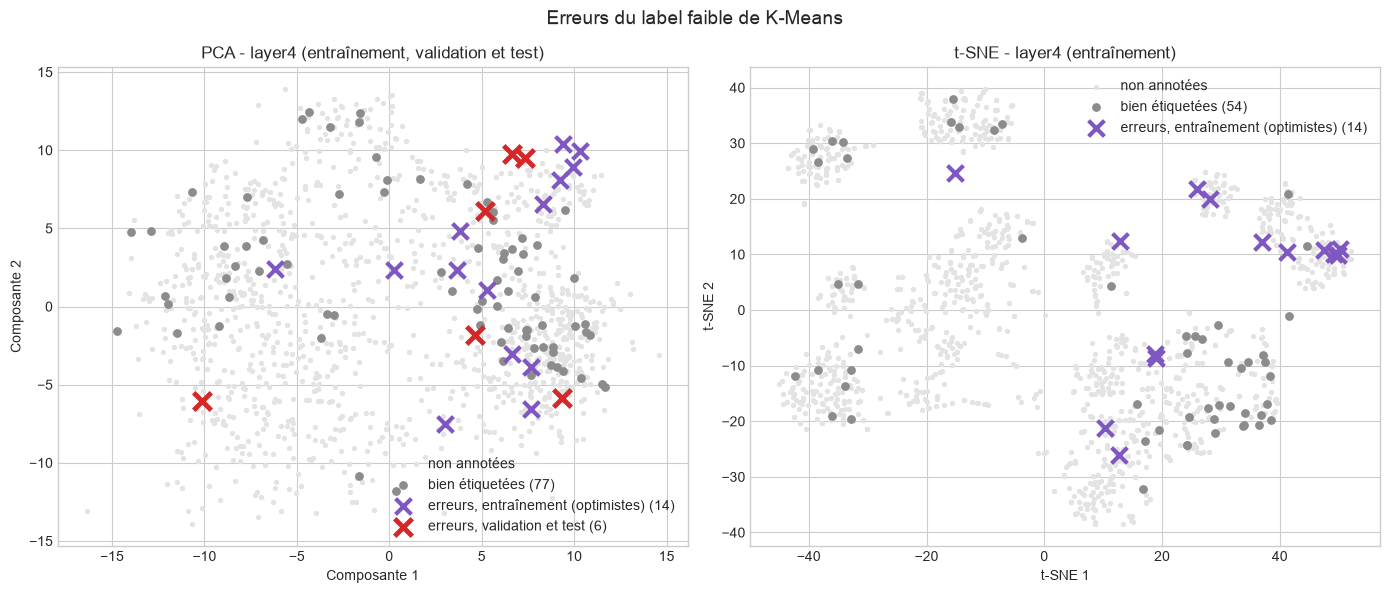

In [26]:
train_positions = np.flatnonzero(is_train)
annotated_results = pd.concat(
    [
        pd.DataFrame(
            {
                "position": positions,
                "image_id": manifest["image_id"].to_numpy()[positions],
                "jeu": split_name,
                "label fort": strong_label[positions].astype(int),
                "label faible": to_weak_labels(clusters, mapping).astype(int),
            }
        )
        for split_name, positions, clusters in (
            (
                "entraînement",
                train_positions[train_labeled],
                kmeans_run["labels"][train_labeled],
            ),
            (
                "validation",
                np.flatnonzero(is_validation),
                assign_clusters(kmeans_run, is_validation),
            ),
            (
                "test",
                np.flatnonzero(is_test),
                assign_clusters(kmeans_run, is_test),
            ),
        )
    ],
    ignore_index=True,
)
annotated_results["erreur"] = (
    annotated_results["label fort"] != annotated_results["label faible"]
)
display(
    annotated_results.groupby("jeu", sort=False)["erreur"].agg(
        erreurs="sum", images="count"
    )
)

errors = annotated_results[annotated_results["erreur"]]
train_index = {position: i for i, position in enumerate(train_positions)}


def plot_errors(axis, coordinates, row_index, unlabeled, title):
    """Nuage 2D : bien étiquetées grisées, erreurs en croix."""
    axis.scatter(
        coordinates[unlabeled, 0],
        coordinates[unlabeled, 1],
        s=8,
        color="#E3E3E3",
        label="non annotées",
    )
    shown = annotated_results["jeu"].isin(row_index["jeux"])
    is_error = annotated_results["erreur"]
    in_training = annotated_results["jeu"] == "entraînement"
    groups = (
        (
            "bien étiquetées",
            shown & ~is_error,
            {"s": 28, "color": "#8C8C8C", "zorder": 2},
        ),
        (
            "erreurs, entraînement (optimistes)",
            shown & is_error & in_training,
            {
                "s": 130,
                "color": "#7E57C2",
                "marker": "x",
                "linewidths": 3,
                "zorder": 3,
            },
        ),
        (
            "erreurs, validation et test",
            shown & is_error & ~in_training,
            {
                "s": 160,
                "color": "#D62728",
                "marker": "x",
                "linewidths": 3.5,
                "zorder": 4,
            },
        ),
    )
    for name, mask, style in groups:
        group = annotated_results[mask]
        if group.empty:
            continue
        rows = [row_index["map"](position) for position in group["position"]]
        axis.scatter(
            coordinates[rows, 0],
            coordinates[rows, 1],
            label=f"{name} ({len(group)})",
            **style,
        )
    axis.set_title(title)
    axis.legend()


figure_errors, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_errors(
    axes[0],
    reduced[REFERENCE_LAYER][:, :2],
    {"jeux": ["entraînement", "validation", "test"], "map": lambda p: p},
    ~is_labeled,
    f"PCA - {REFERENCE_LAYER} (entraînement, validation et test)",
)
plot_errors(
    axes[1],
    tsne_coordinates[REFERENCE_LAYER],
    {"jeux": ["entraînement"], "map": lambda p: train_index[p]},
    ~train_labeled,
    f"t-SNE - {REFERENCE_LAYER} (entraînement)",
)
for axis in axes:
    axis.set(xlabel="Composante 1", ylabel="Composante 2")
axes[1].set(xlabel="t-SNE 1", ylabel="t-SNE 2")
figure_errors.suptitle("Erreurs du label faible de K-Means", fontsize=14)
plt.tight_layout()
figure_errors.savefig(
    FIGURES_DIR / "erreurs-labels-faibles.png", dpi=120, bbox_inches="tight"
)
plt.show()

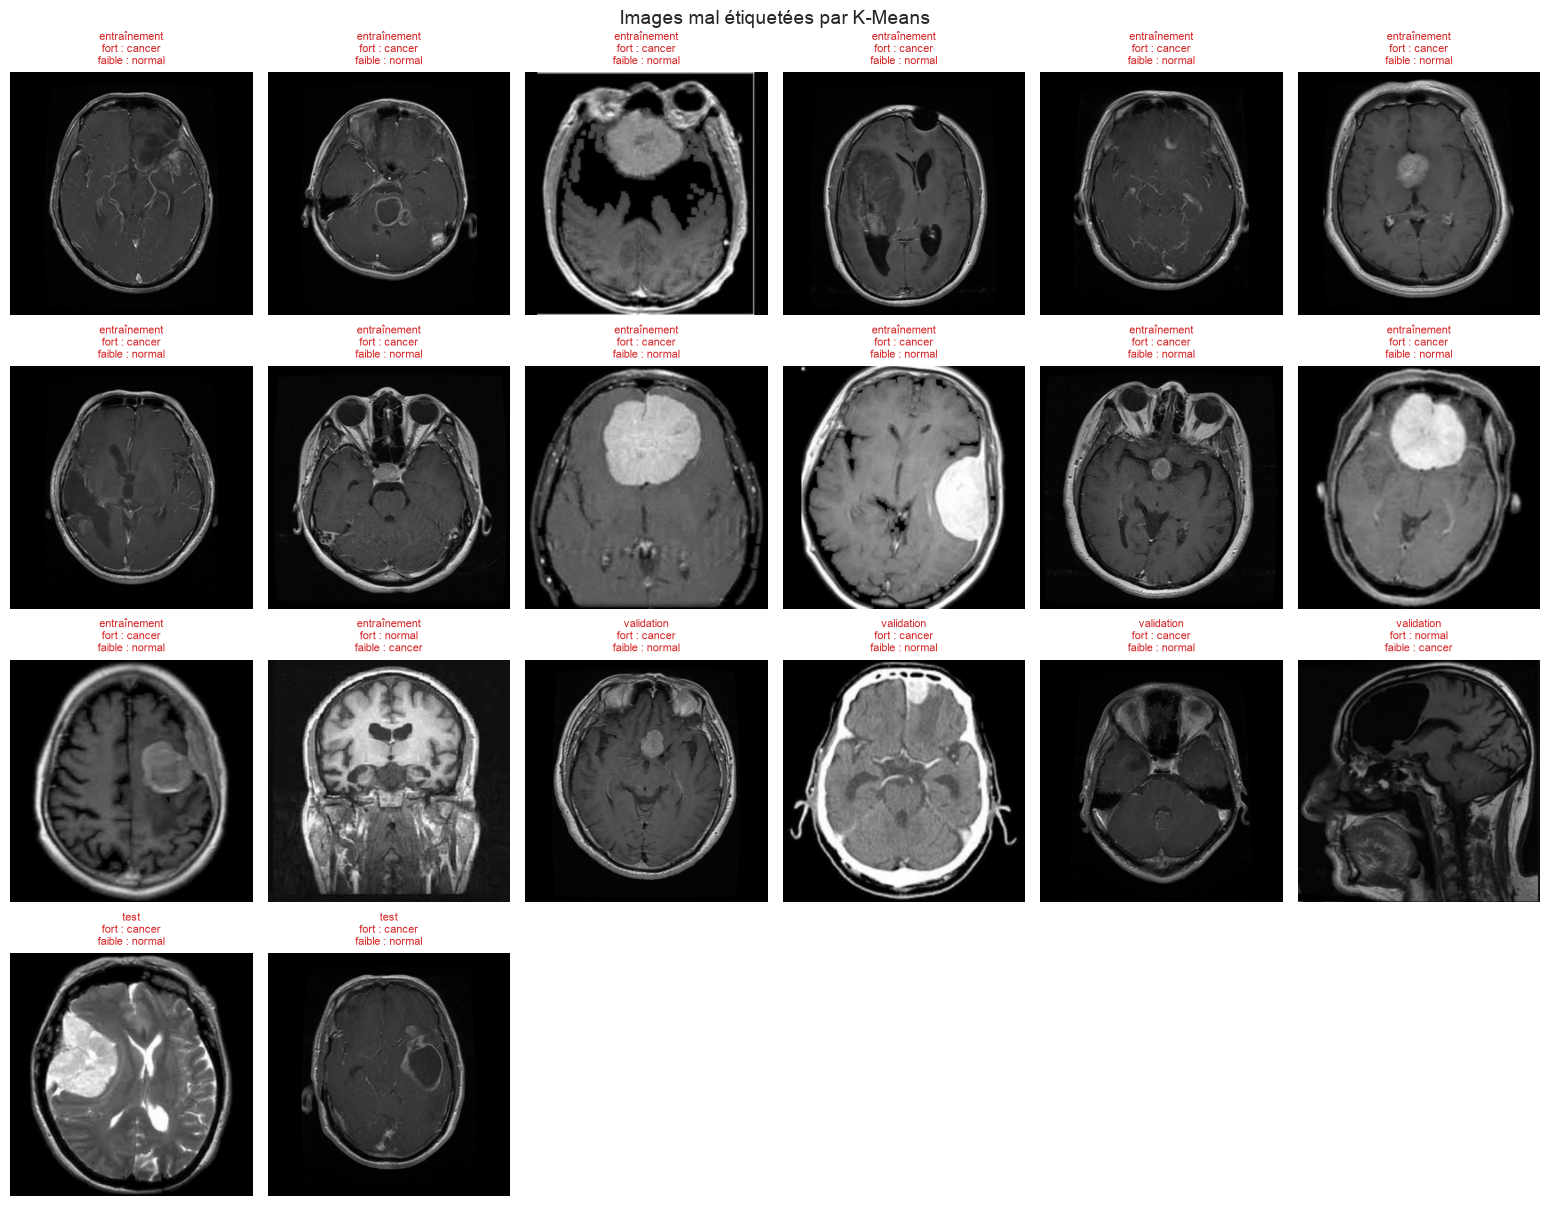

In [27]:
COLUMNS = 6
board_rows = int(np.ceil(len(errors) / COLUMNS))
figure_board, axes = plt.subplots(
    board_rows,
    COLUMNS,
    figsize=(2.6 * COLUMNS, 3.1 * board_rows),
    squeeze=False,
)
for axis in axes.ravel():
    axis.axis("off")
for axis, (_, row) in zip(axes.ravel(), errors.iterrows(), strict=False):
    with Image.open(manifest["filepath"].iloc[row["position"]]) as image:
        axis.imshow(image.convert("L"), cmap="gray")
    axis.set_title(
        f"{row['jeu']}\nfort : {CLASS_NAMES[row['label fort']]}"
        f"\nfaible : {CLASS_NAMES[row['label faible']]}",
        fontsize=8,
        color="#D62728",
    )
figure_board.suptitle("Images mal étiquetées par K-Means", fontsize=14)
plt.tight_layout()
figure_board.savefig(
    FIGURES_DIR / "images-mal-etiquetees.png", dpi=120, bbox_inches="tight"
)
plt.show()

In [28]:
split_keys = {
    "entraînement": "train",
    "validation": "validation",
    "test": "test",
}
evaluation_metrics = {}
for split_name, group in annotated_results.groupby("jeu"):
    key = split_keys[split_name]
    evaluation_metrics[f"{key}_accuracy"] = 1 - group["erreur"].mean()
    evaluation_metrics[f"{key}_recall_cancer"] = recall_score(
        group["label fort"], group["label faible"], pos_label=1
    )
    evaluation_metrics[f"{key}_f1_cancer"] = f1_score(
        group["label fort"], group["label faible"], pos_label=1
    )
# Les mesures du test sont consignées pour mémoire : on ne s'en sert pas
# pour comparer des runs ni en choisir un.
with resume_run(kmeans_run["run_id"]):
    log_metrics(evaluation_metrics)
    log_figure(figure_errors, "erreurs-labels-faibles.png")
    log_figure(figure_board, "images-mal-etiquetees.png")
    log_figure(figure_confusion, "matrices-confusion-labels-faibles.png")

Sur les 29 images jamais vues (validation et test), le label faible se trompe **6 fois** : 5 `cancer` étiquetées `normal` (3 sur 7 à la validation, 2 sur 8 au test) et une `normal` étiquetée `cancer` (à la validation). Sur les 68 images annotées de l'entraînement, il se trompe 14 fois (13 `cancer` étiquetées `normal` et une `normal` étiquetée `cancer`) : cette mesure est optimiste, car le vote de classe a utilisé ces images. Sur la PCA, les erreurs se trouvent surtout dans la partie droite, du côté où les `normal` annotées sont nombreuses : ce sont des `cancer` dont l'image ressemble à celles des `normal`. Plusieurs d'entre elles montrent pourtant une masse claire visible.

## 11. Fiabilité des labels faibles

### Que capturent les clusters ?

Le notebook `01.02` a montré que des indices d'acquisition (luminosité, contraste, part de fond noir) séparent en partie `cancer` et `normal`, malgré l'égalisation. Les clusters pourraient suivre ces indices plutôt que la pathologie, et les labels faibles hériteraient du biais.

On mesure donc, sur les **images d'origine** (non égalisées), l'**AUC** de chaque descripteur pour prédire :

- le **label fort**, sur les 68 annotées de l'entraînement ;
- le **label faible** de K-Means, sur **ces mêmes 68 images** : l'AUC d'une mesure sur 68 images est bien plus incertaine que sur 1 262, donc la comparaison n'a de sens que sur les mêmes images ;
- le label faible sur les 1 262 images de l'entraînement, pour mémoire.

Une AUC de 0,5 signifie que le descripteur ne sépare pas du tout les classes. Un **intervalle à 95 %** (rééchantillonnage des images) accompagne les AUC mesurées sur 68 images. Si l'AUC du label faible est plus éloignée de 0,5 que celle du label fort, le clustering exploite davantage cet indice que ne le fait la pathologie.

In [29]:
def describe_image(filepath):
    """Luminosité, contraste et part de fond de l'image d'origine."""
    with Image.open(filepath) as image:
        gray = np.asarray(image.convert("L"), dtype=float)
    return {
        "luminosité": gray.mean(),
        "contraste": gray.std(),
        "part de fond": (gray < BACKGROUND_LEVEL).mean(),
    }


descriptors = pd.DataFrame(
    [describe_image(path) for path in manifest["filepath"]]
)
train_descriptors = descriptors[is_train].reset_index(drop=True)


def descriptor_auc(binary_labels, mask):
    """AUC de chaque descripteur pour prédire un label binaire, sur `mask`."""
    return train_descriptors[mask].apply(
        lambda column: roc_auc_score(binary_labels[mask], column)
    )


def auc_interval(column, binary_labels, mask, draws=1000):
    """Intervalle à 95 % de l'AUC d'un descripteur, par rééchantillonnage."""
    generator = np.random.default_rng(RANDOM_STATE)
    values = train_descriptors.loc[mask, column].to_numpy()
    targets = binary_labels[mask]
    scores = []
    while len(scores) < draws:
        draw = generator.integers(0, len(values), len(values))
        if len(set(targets[draw])) == 2:
            scores.append(roc_auc_score(targets[draw], values[draw]))
    low, high = np.percentile(scores, [2.5, 97.5])
    return f"[{low:.2f} ; {high:.2f}]"


all_train = np.ones(len(train_descriptors), dtype=bool)
n_labeled = int(train_labeled.sum())
strong_name = f"label fort ({n_labeled} annotées)"
same_name = f"label faible (mêmes {n_labeled})"
all_name = f"label faible ({len(train_descriptors):,} images)".replace(",", " ")
display(
    pd.DataFrame(
        {
            strong_name: descriptor_auc(train_strong, train_labeled),
            same_name: descriptor_auc(train_weak, train_labeled),
            all_name: descriptor_auc(train_weak, all_train),
        }
    ).round(3)
)

display(
    pd.DataFrame(
        {
            strong_name: {
                column: auc_interval(column, train_strong, train_labeled)
                for column in train_descriptors
            },
            same_name: {
                column: auc_interval(column, train_weak, train_labeled)
                for column in train_descriptors
            },
        }
    ).rename_axis("intervalle à 95 %")
)

,label fort (68 annotées),label faible (mêmes 68),label faible (1 262 images)
luminosité,0.334,0.435,0.500
contraste,0.201,0.271,0.412
part de fond,0.552,0.396,0.408


,label fort (68 annotées),label faible (mêmes 68)
intervalle à 95 %,,
luminosité,[0.20 ; 0.46],[0.31 ; 0.57]
contraste,[0.09 ; 0.31],[0.16 ; 0.39]
part de fond,[0.41 ; 0.68],[0.26 ; 0.53]


### La répartition des labels faibles est-elle plausible ?

On compare la part de `cancer` parmi les labels faibles à celle des images annotées de l'entraînement, et on regarde la distribution de la confiance. Les images annotées sont équilibrées à deux images près, mais la répartition des images non annotées est **inconnue** : cette comparaison ne démontre rien, elle signale un écart éventuel.

In [30]:
share = pd.Series(
    {
        "annotées de l'entraînement (labels forts)": np.nanmean(
            train_strong[train_labeled]
        ),
        "non annotées (labels faibles)": (
            weak_labels["weak_label"] == "cancer"
        ).mean(),
    },
    name="part de cancer",
)
display(share.to_frame().round(3))

display(weak_labels.groupby("weak_label")["confidence"].describe().round(3))

,part de cancer
annotées de l'entraînement (labels forts),0.515
non annotées (labels faibles),0.539


,count,mean,std,min,25%,50%,75%,max
weak_label,,,,,,,,
cancer,643.0,0.111,0.050,0.001,0.073,0.119,0.149,0.236
normal,551.0,0.127,0.062,0.003,0.084,0.132,0.174,0.265


## 12. Que regardent les deux groupes ?

Les deux clusters de K-Means ont chacun un centre dans l'espace de la PCA. La **direction** qui va du centre `normal` au centre `cancer` indique ce qui distingue les deux groupes. On la ramène dans l'espace des caractéristiques : on inverse la PCA, puis on divise par l'écart-type de la standardisation (`scaler.scale_`).

Le pooling global étant une moyenne des cartes spatiales de `layer4` (7 × 7), le score d'une image sur cette direction est la **moyenne** d'une carte, obtenue en sommant les 512 cartes de caractéristiques pondérées par la direction. Cette carte est centrée sur le **milieu des deux centres**, c'est-à-dire sur la frontière entre les clusters : un score positif est du côté `cancer`, un score négatif du côté `normal`. Sans ce centrage, le rouge et le bleu seraient arbitraires. L'échelle est **symétrique** (rouge : côté `cancer`, bleu : côté `normal`).

On compare avec la direction des **labels forts** de l'entraînement (centre des `cancer` annotées moins centre des `normal` annotées). Les cartes de `layer4` font 7 × 7 : elles sont **agrandies par interpolation bilinéaire**, donc grossières.

In [31]:
device = select_device()
classifier = load_classifier(device)
scaler, pca = scalers[REFERENCE_LAYER], pcas[REFERENCE_LAYER]
reference_space = train_reduced[REFERENCE_LAYER]

cluster_of_class = {
    class_code: cluster for cluster, class_code in mapping.items()
}
if set(cluster_of_class) != {0, 1}:
    raise ValueError("Chaque classe doit avoir son cluster.")
centers = kmeans_run["model"].cluster_centers_
strong_cancer = reference_space[train_labeled & (train_strong == 1)].mean(
    axis=0
)
strong_normal = reference_space[train_labeled & (train_strong == 0)].mean(
    axis=0
)
directions = {
    "K-Means": (
        centers[cluster_of_class[1]] - centers[cluster_of_class[0]],
        (centers[cluster_of_class[1]] + centers[cluster_of_class[0]]) / 2,
    ),
    "labels forts": (
        strong_cancer - strong_normal,
        (strong_cancer + strong_normal) / 2,
    ),
}
first, second = (direction for direction, _ in directions.values())
print(
    "Similarité cosinus des deux directions : "
    f"{first @ second / np.linalg.norm(first) / np.linalg.norm(second):.3f}"
)


def to_feature_space(direction, midpoint):
    """Ramène une direction de l'espace PCA à l'espace des caractéristiques.

    Returns:
        Les poids `w` (un par canal) et le décalage `b` tels que le score d'une
        image de caractéristiques `f` vaut `w · f + b`, nul au milieu des deux
        centres.
    """
    weights = (direction @ pca.components_) / scaler.scale_
    origin = (
        (0 - scaler.mean_) / scaler.scale_ - pca.mean_
    ) @ pca.components_.T
    return weights, direction @ (origin - midpoint)


feature_space = {
    name: to_feature_space(direction, midpoint)
    for name, (direction, midpoint) in directions.items()
}


def load_input(filepath):
    """Prétraite une image avec le prétraitement retenu."""
    with Image.open(filepath) as image:
        return preprocess_equalized(image)


def directional_map(filepath, name):
    """Carte 7 × 7 dont la moyenne est le score de l'image sur la direction."""
    weights, offset = feature_space[name]
    maps = feature_maps(classifier, load_input(filepath), "layer4").numpy()
    return np.tensordot(weights, maps, axes=(0, 0)) + offset


# Contrôle : la moyenne de la carte est le score calculé par le chemin direct.
position = int(annotated_results.iloc[0]["position"])
direction, midpoint = directions["K-Means"]
projected = pca.transform(
    scaler.transform(raw_features[REFERENCE_LAYER][position : position + 1])
)[0]
direct_score = direction @ (projected - midpoint)
map_score = directional_map(
    manifest["filepath"].iloc[position], "K-Means"
).mean()
print(
    f"Score direct : {direct_score:.3f}, moyenne de la carte : {map_score:.3f}"
)
if not np.isclose(direct_score, map_score, rtol=1e-2, atol=1e-2):
    raise ValueError("La carte ne reproduit pas le score de l'image.")

Similarité cosinus des deux directions : 0.713
Score direct : 137.992, moyenne de la carte : 137.992


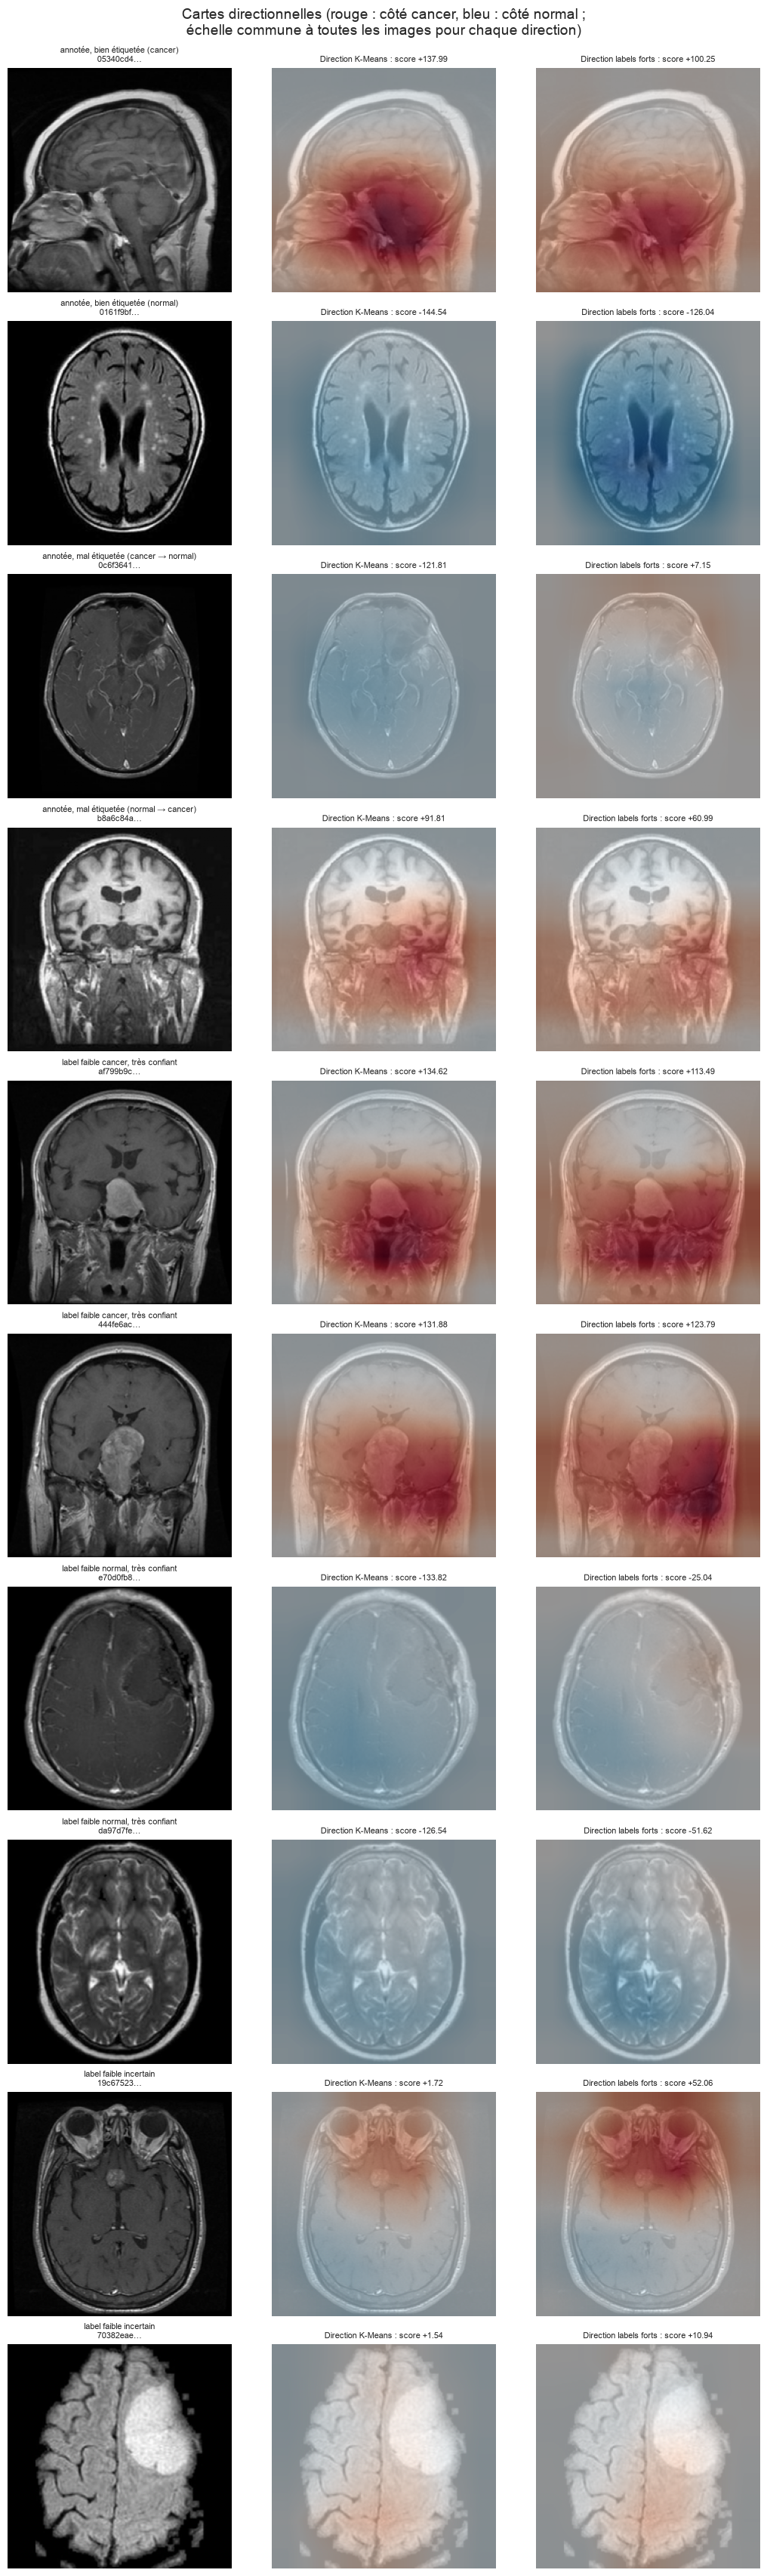

In [32]:
well_labeled = annotated_results[~annotated_results["erreur"]]
mislabeled = annotated_results[annotated_results["erreur"]]

selection = [
    (
        f"annotée, bien étiquetée ({CLASS_NAMES[code]})",
        well_labeled[well_labeled["label fort"] == code].iloc[0]["image_id"],
    )
    for code in (1, 0)
]
for code in (1, 0):
    group = mislabeled[mislabeled["label fort"] == code]
    if len(group):
        selection.append(
            (
                f"annotée, mal étiquetée ({CLASS_NAMES[code]} → {CLASS_NAMES[1 - code]})",
                group.iloc[0]["image_id"],
            )
        )
for label in ("cancer", "normal"):
    for image_id in by_confidence[by_confidence["weak_label"] == label].head(2)[
        "image_id"
    ]:
        selection.append((f"label faible {label}, très confiant", image_id))
for image_id in by_confidence.tail(2)["image_id"]:
    selection.append(("label faible incertain", image_id))

cams = {
    (image_id, name): directional_map(by_id.loc[image_id, "filepath"], name)
    for _, image_id in selection
    for name in directions
}
# Une limite par direction, commune à toutes les images : les couleurs se
# comparent d'une image à l'autre.
limits = {
    name: max(
        np.abs(cam).max()
        for (_, cam_name), cam in cams.items()
        if cam_name == name
    )
    for name in directions
}

figure_cam, axes = plt.subplots(
    len(selection),
    3,
    figsize=(10.5, 3.4 * len(selection)),
    layout="constrained",
)
for row, (group_name, image_id) in enumerate(selection):
    path = by_id.loc[image_id, "filepath"]
    with Image.open(path) as image:
        base = np.asarray(image.convert("L").resize((IMAGE_SIZE, IMAGE_SIZE)))
    axes[row, 0].imshow(base, cmap="gray")
    axes[row, 0].set_title(f"{group_name}\n{image_id[:8]}…", fontsize=8)
    for column, name in enumerate(directions, start=1):
        cam = cams[image_id, name]
        shown = cv2.resize(
            cam.astype(np.float32),
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_LINEAR,
        )
        axes[row, column].imshow(base, cmap="gray")
        axes[row, column].imshow(
            shown,
            cmap="RdBu_r",
            vmin=-limits[name],
            vmax=limits[name],
            alpha=0.6,
        )
        axes[row, column].set_title(
            f"Direction {name} : score {cam.mean():+.2f}", fontsize=8
        )
for axis in axes.ravel():
    axis.axis("off")
figure_cam.suptitle(
    "Cartes directionnelles (rouge : côté cancer, bleu : côté normal ;\n"
    "échelle commune à toutes les images pour chaque direction)",
    fontsize=14,
)
figure_cam.savefig(
    FIGURES_DIR / "cartes-directionnelles.png", dpi=110, bbox_inches="tight"
)
plt.show()
with resume_run(kmeans_run["run_id"]):
    log_figure(figure_cam, "cartes-directionnelles.png")

- **Zones.** Les zones rouges (côté `cancer`) se trouvent surtout au centre et en bas de la tête (base du crâne, région du visage), les zones bleues (côté `normal`) sur l'ensemble du cerveau. Sur les deux coupes coronales très confiantes, la zone rouge recouvre la région de la tumeur sans s'y limiter et s'étend horizontalement jusqu'aux bords de l'image : les cartes ne localisent pas la lésion, et semblent suivre la position dans l'image plus que la structure visible. La résolution de `layer4` (7 × 7) est une explication possible, que ce notebook ne démontre pas.
- **Deux directions.** Leur similarité cosinus est de 0,71. Elles donnent des cartes proches pour les images annotées bien étiquetées, et divergent pour la `cancer` mal étiquetée (score de K-Means de -122, score des labels forts à peine positif, +7) et pour les images au label faible incertain, dont le score de K-Means est proche de 0. Leur carte est alors pâle, avec de faibles zones rouges et bleues qui se compensent : le score n'est que la moyenne de la carte.
- **Échelle.** La limite de couleur est commune à toutes les images pour une direction donnée : les couleurs se comparent d'une image à l'autre. Elle est fixée par les pics les plus forts, côté `cancer` : à score comparable, les cartes du côté `normal` paraissent plus pâles.
- **Plan de coupe.** Sur ces dix images, les scores les plus élevés côté `cancer` sont des coupes sagittales ou coronales, et les plus bas côté `normal` des coupes axiales : le groupe semble suivre le plan de coupe autant que la pathologie. Les deux images mal étiquetées vont dans ce sens : la `cancer` classée `normal` est une coupe axiale, la `normal` classée `cancer` une coupe coronale. Sans métadonnées, on ne peut pas le vérifier.

## Conclusion de l'étape

### Synthèse

- **Découpage.** L'entraînement compte 1 262 images (68 annotées, dont 35 `cancer` et 33 `normal`, et 1 194 non annotées), la validation 14 images (7 + 7) et le test 15 images (8 `cancer` et 7 `normal`). Les trois jeux sont disjoints et définis avant toute transformation. La standardisation et la PCA sont ajustées sur l'entraînement seul : les 50 composantes retenues portent **84,4 %** de la variance pour `layer3` et **73,0 %** pour `layer4`.
- **Structure visible.** Sur `layer4`, les `normal` annotées se regroupent surtout dans une zone de la PCA et du t-SNE, et les `cancer` sont plus dispersées, avec un recouvrement. Sur `layer3`, les `cancer` forment surtout des îlots à gauche et en bas.
- **`layer4` est la meilleure couche pour le clustering.** K-Means y obtient un ARI de **0,337**, contre **0,092** sur `layer3`. Aucun nombre de clusters entre 2 et 6 ne se détache (ARI de 0,21 à 0,36 sur `layer4`, silhouette voisine de 0,12), et on garde `k = 2`.

La comparaison des deux méthodes sur `layer4` donne (ARI hors bruit pour DBSCAN) :

| Méthode | Clusters | Couverture à l'entraînement | ARI entraînement | ARI validation | ARI test |
|---|---|---|---|---|---|
| K-Means | 2 | 100 % | 0,337 | 0,122 | 0,504 |
| DBSCAN | 3 | 84 % | 0,266 | non évalué | non évalué |

- **K-Means** est stable : même ARI pour 10, 20 et 50 composantes comme pour les features complètes (0,337 sur `layer4`) et même résultat pour 10 seeds (ARI minimal de 1,000 sur `layer3`, 0,994 sur `layer4`). Un ARI d'environ 0,3 est meilleur que le hasard (0) mais loin d'un accord parfait (1).
- **DBSCAN** suppose des zones denses, ce que le nuage de points n'offre pas : sur `layer4`, une seule des 12 configurations forme plusieurs clusters (trois), les autres n'en forment qu'un, et la configuration retenue laisse 16 % des images sans classe. Son ARI (0,266) porte sur 47 images annotées sur 68 et reste inférieur à celui de K-Means (0,337).
- **Seuil de décision.** Choisi sur l'entraînement (rappel de `cancer` maximal avec au plus 20 % de fausses alertes), le seuil de 0,53 fait passer le rappel de 0,63 à 0,71 sur l'entraînement (exactitude inchangée à 0,79, fausses alertes de 3 % à 12 %), mais ne change rien sur la validation (rappel de 0,57, fausses alertes de 14 %). Le gain ne se confirme pas : on garde le seuil de 0,50.
- **Labels faibles.** Les 1 194 images non annotées reçoivent **643 `cancer` et 551 `normal`**, soit 54 % de `cancer` contre 51 % parmi les annotées de l'entraînement. La répartition réelle des non annotées est inconnue.
- **Exactitude du label faible** (K-Means) : **0,794** sur l'entraînement (optimiste, le vote utilise ces images), **0,714** sur la validation (10 images sur 14, intervalle de confiance à 95 % de 0,454 à 0,883) et **0,867** sur le test (13 sur 15, intervalle de 0,621 à 0,963). La précision de `cancer` vaut 0,800 sur la validation et 1,00 sur le test, son rappel **0,57** et **0,75**. Sur les 29 images jamais vues, le label faible se trompe 6 fois : 5 `cancer` étiquetées `normal` et une `normal` étiquetée `cancer` ; sur les 68 annotées de l'entraînement, 14 fois (mesure optimiste).
- **Confiance.** Elle est faible : médiane de **0,12** pour `cancer` et **0,13** pour `normal`, maximum de **0,27**. Sur les 1 194 labels faibles, 428 sont indécis (confiance sous 0,10), 688 hésitants et **78 seulement confiants** (0,20 et plus). Parmi les images les plus confiantes, plusieurs montrent une masse visible dans le label faible `normal`.
- **Ce que capturent les clusters.** Sur les 68 mêmes images annotées, les labels faibles suivent la luminosité et le contraste un peu moins que les labels forts (AUC de 0,435 contre 0,334 pour la luminosité, de 0,271 contre 0,201 pour le contraste), avec des intervalles à 95 % qui se recouvrent largement : on ne peut pas montrer que le clustering exploite moins ces indices d'acquisition que la pathologie. Pour la part de fond, les AUC diffèrent (0,396 contre 0,552) mais les intervalles se recouvrent aussi. Sur les 1 262 images, les AUC des labels faibles sont plus proches de 0,5 (0,500, 0,412 et 0,408), ce qui ne se compare pas aux labels forts, mesurés sur 68 images. Les cartes directionnelles montrent des zones centrées sur le centre et le bas de la tête, sans se limiter à la lésion et, sur les coupes coronales, jusqu'aux bords de l'image, et les groupes semblent suivre le plan de coupe (sagittal ou coronal côté `cancer`, axial côté `normal`) autant que la pathologie.

### Décision

**K-Means** (couche `layer4`, 50 composantes, `k = 2`, seuil de 0,50, seed fixe) est la référence et la **seule source de labels faibles**, pour trois raisons :

1. il attribue une classe à **toutes** les images, alors que DBSCAN laisse des images sans cluster, donc sans classe ;
2. il produit directement **deux groupes**, comme les deux classes du jeu annoté ;
3. il est **stable** : même ARI pour 10, 20 et 50 composantes comme pour les features complètes, et même résultat pour 10 seeds. Son ARI sur la validation et le test (0,122 et 0,504) varie beaucoup, avec 14 et 15 images.

DBSCAN reste dans le notebook à titre de comparaison.

À l'étape suivante, les labels faibles sont à utiliser avec prudence : exactitude de 0,71 à 0,87 sur des images jamais vues (14 et 15 images), rappel de `cancer` de 0,57 à 0,75, confiance faible, clusters qui suivent en partie la luminosité et le contraste, proportion de `cancer` non vérifiable et jeu annoté peu nombreux. Le jeu de validation (14 images) sert à l'arrêt anticipé, et le modèle semi-supervisé est comparé à un modèle entraîné **sans** labels faibles. Les clusterings de ce notebook sont suivis dans MLflow (`make mlflow-ui`).